# ViT · 03-3: Ground Truth — stimmen die Karten?

- **Voraussetzung:** [03-0](keith_03-0_vit-probly.ipynb) ist ausgeführt (Merkmale und Köpfe sind gespeichert).
- **Problem:** In 03-1 haben wir Karten für P, TU, AU und EU gezeigt. Ob sie **stimmen**, wissen wir nicht: Bei echten
  Fotos weiß niemand, welcher Bildteil das Modell „wirklich“ unsicher macht. Der Vergleich mit den Trimaps (F3) sagt
  nur grob „eher auf dem Tier“.
- **Idee:** Wir bauen Testbilder, deren Ursache wir **selbst einbauen**. So wie früher die synthetischen
  Tabellendaten mit eingebauter Lücke. Dann wissen wir, wo die Ursache liegt, und können prüfen, ob die Erklärung sie
  findet.

### Drei Testbilder, jeweils mit Kontrolle

| Test | Wie wir das Bild bauen | Kontrolle | Was wir erwarten |
|---|---|---|---|
| **Fremdes Muster** | Schachbrett-Flicken (48 × 48 Pixel) auf dem Hintergrund | natürlicher Hintergrund-Flicken aus einem anderen Bild, gleiche Stelle | EU steigt genau am Flicken, bei der Kontrolle nicht |
| **Zwei Rassen** | linke Hälfte Rasse A, rechte Hälfte Rasse B | rechte Hälfte aus einem anderen Bild **derselben** Rasse A | AU steigt nur, wenn beide Hälften **zusammen** sichtbar sind: ein positives Paar |
| **Chimäre** | Kopf von Rasse A auf den Körper von Rasse B (Kopf-Rahmen aus `annotations/xmls`) | Kopf aus einem anderen Bild **derselben** Rasse B, gleich eingeklebt | EU steigt nur bei Kopf und Körper **zusammen**: ein positives Paar |

**Warum jedes Mal eine Kontrolle?** Jede Konstruktion verändert das Bild auch auf andere Weise: Ein Flicken verdeckt
Hintergrund, eine Klebekante ist eine harte Linie. Die Kontrolle hat dieselbe Konstruktion, nur **ohne** die Ursache.
Was sich zwischen Test und Kontrolle unterscheidet, kommt von der Ursache und nicht vom Basteln.

### Zwei Stufen, getrennt geprüft

1. **Reagiert das Modell?** Wir vergleichen die Spielwerte mit und ohne Ursache. Steigt die EU gar nicht, kann auch
   keine Erklärung sie zeigen. Das wäre dann kein Fehler des Explainers, sondern eine Eigenschaft des Modells.
2. **Findet die Erklärung die Ursache?** Wir prüfen die Shapley-Werte und Paare an der bekannten Stelle.

**Was wir sicher wissen und was nur vermutet ist:** Wir wissen, **wo** die Ursache liegt und ob sie **zwei Teile
zusammen** braucht. Ob sie als **AU oder EU** erscheint, ist dagegen unsere Vermutung. Genau die testen wir.

### Zwei Arten von Spielern

- **Grob und exakt:** Die Spieler sind die Teile, aus denen wir das Bild gebaut haben (Flicken / Tier / Hintergrund,
  links / rechts, Kopf / Körper / Hintergrund). Bei 2 oder 3 Spielern gibt es nur 4 oder 8 Koalitionen; shapiq rechnet
  die Werte **exakt** (`ExactComputer`). So ist die Ground Truth nicht durch eine Näherung verwischt, und die Rechnung
  kostet fast nichts.
- **Fein, wie im Alltag:** 16 SLIC-Superpixel, k-SII bis Ordnung 2, Budget 1000, genau wie in 03-1. Damit prüfen wir,
  ob auch die normale Pipeline die Ursache findet, ohne dass wir ihr die Teile vorgeben.

**Mehr shapiq (Abschnitte 7 bis 9, ergänzt am 25./26.11.):** dieselben groben Spiele mit vier Indizes (k-SII, STII,
FSII, Möbius), das Chimären-Paar mit 16 Superpixeln, und die Chimäre in shapiqs eigenen Plots.

### Vorab festgelegte Fragen (mit Keith abgestimmt am 25.11.2026, vor jeder Rechnung)

| | Frage | Regel für „gestützt“ |
|---|---|---|
| F8 | Findet die feine EU-Karte das fremde Muster? | Das Superpixel des Flickens hat in **≥ 50 %** der Bilder den **höchsten** EU-Wert (Zufall: 1/16 ≈ 6 %), und das häufiger als bei der Kontrolle |
| F9 | Zeigen zwei Rassen ein AU-Paar? | Das Paar links × rechts ist für AU in **≥ 80 %** der Bilder positiv, **und** sein Median liegt über dem der Kontrolle |
| F10 | Zeigt die Chimäre ein EU-Paar? | Das Paar Kopf × Körper ist für EU in **≥ 2/3** der Bilder positiv, **und** sein Median liegt über dem der Kontrolle |
| F11 | Trennt die Zerlegung „Widerspruch“ von „nie gesehen“? | Bei Chimären ist der EU-Anteil am Paar (EU-Paar / TU-Paar) im Median **größer** als bei zwei Rassen |
| F12 | Hängt das Chimären-Paar am Index? (grob, exakt) | Das EU-Paar Kopf × Körper ist bei **allen vier** Indizes (k-SII, STII, FSII, Möbius) in **≥ 2/3** der Chimären positiv **und** sein Median liegt über dem der Kontrolle |
| F13 | Findet auch die normale Pipeline (16 SLIC-Superpixel) das Chimären-Paar? | Die **Summe der EU-Paare** zwischen allen Kopf- und allen Körper-Superpixeln ist in **≥ 2/3** der Chimären positiv **und** ihr Median liegt über dem der Kontrolle. Jedes Superpixel gehört zu dem groben Teil mit den meisten seiner Pixel; hat Kopf oder Körper kein Superpixel, zählt das Bild als „nicht positiv“ |

**F12 und F13 kamen später dazu** (mit Keith abgestimmt am 25.11.2026 gegen 22:10, vor jeder Rechnung zu F12 und
F13). Ehrlich gesagt: Das Ergebnis von F10 kannten wir da schon. F12 prüft also, ob ein bekanntes Ergebnis von der
Wahl des Index abhängt; F13 ist eine neue Messung mit Bildern, die vorher nie fein erklärt wurden.

**Warum F11 die spannendste Frage ist:** Bei beiden Bildern widersprechen sich die Hinweise (zwei Rassen in einem Bild).
Nur bei der Chimäre ist die **Kombination** nie vorgekommen; das ist die Bild-Version der „epistemischen Interaktion“
aus dem Projektplan (N1). Wenn die Zerlegung diesen Unterschied sieht, ist das eine starke Aussage. Wenn nicht,
berichten wir das genauso.

**Eine Erwartung, die wir vorab aufschreiben (zu F9):** Ist alles ausgeblendet, ist das Modell fast maximal unsicher
(TU ≈ 3,45 nats, 03-0). Schon **eine** Hälfte senkt die Unsicherheit stark, die zweite Hälfte senkt sie dann nur noch
wenig. Dadurch ist das Paar für TU und AU **schon bei der Kontrolle positiv** („doppelt gemoppelt“, Redundanz). Der
erste Teil der Regel F9 ist darum leicht zu erfüllen. Aussagekräftig ist der **Vergleich mit der Kontrolle**: Nur dort
unterscheidet sich, ob die zweite Hälfte eine **andere** Rasse zeigt.

**Umfang:** je 30 Testbilder und 30 Kontrollen für die groben Tests, davon je 20 für die feinen SLIC-Erklärungen beim
Muster-Test (F8) und beim Chimären-Test (F13). Es wird **nichts neu trainiert**; erklärt wird die Hauptmethode aus 03-1: `Gemischt` mit maskierten Köpfen.

### Entscheidungen und warum

| Entscheidung | Warum |
|---|---|
| **Quellbilder aus der Validierung** | Die Köpfe wurden auf den Trainingsbildern trainiert. Würden wir Trainingsbilder zerschneiden, kennt das Modell die Teile schon. Die Testbilder (Testsplit) haben keine Kopf-Rahmen; die gibt es nur in `trainval`. |
| **Nur Quellbilder, die das Modell sicher richtig erkennt** (richtig und P(wahre Rasse) ≥ 0,5) | Sonst wissen wir nicht, ob ein Teil „Rasse A“ sagt. Die Ursache soll die eingebaute sein, nicht ein schon schwieriges Foto. |
| **Schachbrett 48 × 48, Felder 8 Pixel** | Eine scharfe, regelmäßige Textur, die in keinem Tierfoto vorkommt. 48 Pixel = 3 × 3 ViT-Tokens; die Position liegt auf dem 16-Pixel-Raster, der Flicken deckt also ganze ViT-Tokens ab. Mit 4,6 % der Bildfläche bleibt das Tier ganz sichtbar. |
| **Flicken auf den Hintergrund** (≥ 90 % Hintergrund laut Trimap) | Das Tier soll nicht verdeckt werden, sonst ändert sich die Vorhersage aus einem anderen Grund. |
| **Kontroll-Flicken: echter Hintergrund aus einem anderen Bild** | Gleiche Größe, gleiche Stelle, gleiche Klebekante, aber eine Textur, wie sie in den Trainingsdaten vorkommt. |
| **Zwei Rassen: der mittlere Streifen (Spalten 56 bis 168) jedes Bildes** | Die Tiere sind meist mittig, der Streifen zeigt also das meiste vom Tier. 112 Pixel = 7 ViT-Tokens = 8 DINOv2-Tokens: Die Grenze liegt für beide Netze genau auf einer Token-Grenze. |
| **Zwei Rassen: gleiche Tierart** (Katze mit Katze, Hund mit Hund) | Hund neben Katze wäre zu leicht; ähnliche Rassen sind der interessante Fall. |
| **Chimäre: Kopf-Rahmen aus `annotations/xmls`**, auf die Größe des Ziel-Rahmens gebracht | Oxford Pets liefert diese Rahmen mit. Der Kopf landet genau dort, wo vorher der echte Kopf war. |
| **Chimäre: Kopf 40 bis 170 Pixel, Körper ≥ 10 % des Bildes** | Ohne echten Körper (Nahaufnahmen) ergibt ein Paar Kopf × Körper keinen Sinn. Festgelegt vor jeder Rechnung. |
| **Jeder grobe Spieler braucht Tokens in beiden Netzen** | Ein Spieler ohne Tokens lässt sich nicht ausblenden; er wäre automatisch ein Dummy. |
| **Ziehung mit festem Seed** (`default_rng([0, Testnummer])`) | Wiederholbar, und nicht nach Ergebnis ausgesucht. |

## 0. Setup

In [1]:
from __future__ import annotations

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapiq
import torch
from IPython.display import Markdown, display

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "probly").is_dir())
PACKAGE_DIR = REPO_ROOT / "experiments" / "group-d_experiments" / "keith_03_vit_uncertainty"
sys.path.insert(0, str(PACKAGE_DIR))

from vit_uncertainty import (
    FeatureLayout,
    OxfordPets,
    UncertaintyExplainer,
    UncertaintyExplanation,
    build_methods,
    default_data_root,
    load_backbones,
    make_regions,
    plot_pairs,
    plot_prediction_and_uncertainty,
    settings,
)
from vit_uncertainty import ground_truth as gt
from vit_uncertainty.features import ARTIFACT_DIR, full_image_features, load
from vit_uncertainty.plot import region_boundaries, show_values, superpixel_patches
from vit_uncertainty.probly_bridge import uncertainty

torch.set_num_threads(max(1, torch.get_num_threads()))
FIGURES = PACKAGE_DIR / "figures"
FIGURES.mkdir(exist_ok=True)

pets = OxfordPets(default_data_root())
backbones = load_backbones()
layout = FeatureLayout.from_backbones(backbones)
stored = load(ARTIFACT_DIR / "heads.pt")
if stored is None:
    raise FileNotFoundError("heads.pt fehlt. Bitte zuerst keith_03-0_vit-probly.ipynb ausführen.")
# The main configuration of 03-1: mixed ensemble (3 ViT + 3 DINOv2 heads), heads that know partial images.
predictor = build_methods(layout, stored["heads"]["maskiert"], n_members=settings.N_MEMBERS)["Gemischt"]
METHOD = "Gemischt (maskiert)"

N_IMAGES = 30  # test images (and as many controls) per test
N_FINE = 20  # of them, explained with 16 SLIC superpixels in the pattern test

# The pre-registered rules F8 to F11 (see the table above), as numbers.
RULES = {"F8_top1": 0.5, "F9_positive": 0.8, "F10_positive": 2 / 3}
print("Hauptmethode:", METHOD, "| Testbilder je Test:", N_IMAGES, "| davon fein erklärt:", N_FINE)

/home/claude/sep-trustworthy-gruppe-d/probly/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Hauptmethode: Gemischt (maskiert) | Testbilder je Test: 30 | davon fein erklärt: 20


## 1. Quellbilder: Validierungsbilder, die das Modell sicher richtig erkennt

Die Merkmale der vollständigen Bilder liegen schon im Cache von 03-0; diese Auswahl kostet keine Transformer-Läufe.

In [2]:
ids, labels, species = pets.trainval
_, val_pos = pets.train_val_indices
full = full_image_features(pets, backbones, "trainval", verbose=False)
x_val = layout.concat({name: full["features"][name][val_pos] for name in layout.names})
p_val = uncertainty(predictor, x_val)["probabilities"]
p_true = p_val[np.arange(len(val_pos)), labels[val_pos]]
recognized = (p_val.argmax(1) == labels[val_pos]) & (p_true >= 0.5)
pool = [int(val_pos[k]) for k in np.flatnonzero(recognized)]
boxes = {i: pets.load_head_box(ids[i]) for i in pool}
box_pool = [i for i in pool if gt.head_box_usable(boxes[i])]
print(
    f"Validierungsbilder: {len(val_pos)} | sicher richtig erkannt: {len(pool)} "
    f"({len(pool) / len(val_pos):.0%}) | davon mit brauchbarem Kopf-Rahmen: {len(box_pool)}"
)


def breed(i: int) -> str:
    return pets.classes[int(labels[i])]

Validierungsbilder: 736 | sicher richtig erkannt: 699 (95%) | davon mit brauchbarem Kopf-Rahmen: 376


## 2. Die Testbilder bauen

Für jeden Test ziehen wir mit festem Seed. Test und Kontrolle teilen sich immer das **Grundbild**: beim Muster dasselbe
Bild und dieselbe Stelle, bei zwei Rassen dieselbe linke Hälfte, bei der Chimäre denselben Körper. So unterscheiden
sich Test und Kontrolle wirklich nur in der eingebauten Ursache.

In [3]:
# --- Test 1: foreign pattern. Base image k gets a checkerboard (test) or a natural background patch (control).
rng = np.random.default_rng([settings.SEED, 1])
candidates = [i for i in rng.permutation(pool) if gt.background_positions(pets.load_trimap(ids[i]))]
bases, donors = candidates[:N_IMAGES], candidates[N_IMAGES : 2 * N_IMAGES]
pattern = {"test": [], "kontrolle": []}
for base, donor in zip(bases, donors, strict=True):
    trimap = pets.load_trimap(ids[base])
    positions = gt.background_positions(trimap)
    position = positions[rng.integers(len(positions))]
    donor_positions = gt.background_positions(pets.load_trimap(ids[donor]))
    r, c = donor_positions[rng.integers(len(donor_positions))]
    natural = pets.load_crop(ids[donor])[r : r + gt.PATCH_SIZE, c : c + gt.PATCH_SIZE]
    crop = pets.load_crop(ids[base])
    info = {"Bild": ids[base], "Rasse": breed(base), "Spender": ids[donor], "Stelle": position}
    for variant, patch in (("test", gt.checkerboard()), ("kontrolle", natural)):
        pattern[variant].append(gt.make_pattern_image(crop, trimap, patch, position, variant=variant, sources=info))

# --- Test 2: two breeds. Same left half; right half of another breed (test) or of the same breed (control).
rng = np.random.default_rng([settings.SEED, 2])
two = {"test": [], "kontrolle": []}
for left in rng.permutation(pool):
    if len(two["test"]) == N_IMAGES:
        break
    other_breed = [j for j in pool if species[j] == species[left] and labels[j] != labels[left]]
    same_breed = [j for j in pool if labels[j] == labels[left] and j != left]
    if not other_breed or not same_breed:
        continue
    right_test = other_breed[rng.integers(len(other_breed))]
    right_control = same_breed[rng.integers(len(same_breed))]
    crop_left = pets.load_crop(ids[left])
    for variant, right in (("test", right_test), ("kontrolle", right_control)):
        info = {"links": ids[left], "rechts": ids[right], "Rasse links": breed(left), "Rasse rechts": breed(right)}
        two[variant].append(
            gt.make_two_breeds_image(crop_left, pets.load_crop(ids[right]), variant=variant, sources=info)
        )

# --- Test 3: chimera. Same body; head of another breed (test) or of another image of the same breed (control).
rng = np.random.default_rng([settings.SEED, 3])
chimera = {"test": [], "kontrolle": []}
for body in rng.permutation(box_pool):
    if len(chimera["test"]) == N_IMAGES:
        break
    trimap = pets.load_trimap(ids[body])
    other_breed = [j for j in box_pool if species[j] == species[body] and labels[j] != labels[body]]
    same_breed = [j for j in box_pool if labels[j] == labels[body] and j != body]
    if not other_breed or not same_breed:
        continue
    head_test = other_breed[rng.integers(len(other_breed))]
    head_control = same_breed[rng.integers(len(same_breed))]
    built = {}
    for variant, head in (("test", head_test), ("kontrolle", head_control)):
        info = {"Kopf": ids[head], "Körper": ids[body], "Rasse Kopf": breed(head), "Rasse Körper": breed(body)}
        built[variant] = gt.make_chimera_image(
            pets.load_crop(ids[head]),
            boxes[head],
            pets.load_crop(ids[body]),
            boxes[body],
            trimap,
            variant=variant,
            sources=info,
        )
    players = built["test"].players  # identical for test and control (same body, same box)
    if (players == 1).mean() < gt.MIN_BODY_SHARE or not gt.players_have_tokens(players, backbones):
        continue
    for variant in built:
        chimera[variant].append(built[variant])

tests = {"muster": pattern, "zwei_rassen": two, "chimaere": chimera}
for kind, images in tests.items():
    usable = all(gt.players_have_tokens(t.players, backbones) for v in images.values() for t in v)
    print(
        f"{kind:12s}: {len(images['test'])} Testbilder + {len(images['kontrolle'])} Kontrollen; "
        f"alle Spieler haben Tokens: {usable}"
    )

muster      : 30 Testbilder + 30 Kontrollen; alle Spieler haben Tokens: True
zwei_rassen : 30 Testbilder + 30 Kontrollen; alle Spieler haben Tokens: True
chimaere    : 30 Testbilder + 30 Kontrollen; alle Spieler haben Tokens: True


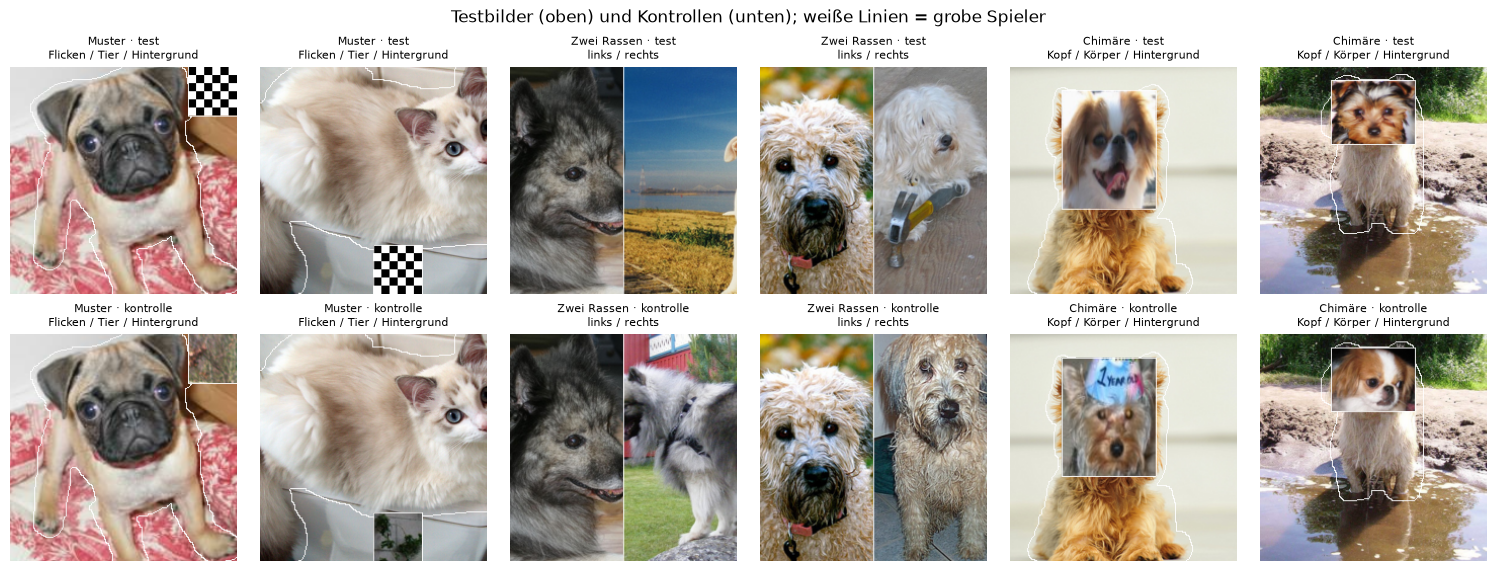

In [4]:
def show_players(ax: plt.Axes, test: gt.TestImage, title: str) -> None:
    # The image with the borders of its coarse players (white lines).
    ax.imshow(test.image)
    overlay = np.zeros((*test.players.shape, 4))
    overlay[region_boundaries(test.players)] = (1, 1, 1, 0.9)
    ax.imshow(overlay)
    ax.set_title(title, fontsize=8)
    ax.axis("off")


fig, axes = plt.subplots(2, 6, figsize=(15, 5.6), layout="constrained")
for column, (kind, label) in enumerate((("muster", "Muster"), ("zwei_rassen", "Zwei Rassen"), ("chimaere", "Chimäre"))):
    for row, variant in enumerate(("test", "kontrolle")):
        for k in range(2):
            t = tests[kind][variant][k]
            show_players(axes[row, 2 * column + k], t, f"{label} · {variant}\n{' / '.join(t.player_names)}")
fig.suptitle("Testbilder (oben) und Kontrollen (unten); weiße Linien = grobe Spieler")
fig.savefig(FIGURES / "ground_truth_testbilder.png", dpi=100)
plt.show()

## 3. Grob und exakt: alle Koalitionen jedes Testbildes

Für jedes Bild (Test und Kontrolle) rechnet der `UncertaintyExplainer` mit den groben Spielern. Das Budget ist
2ⁿ (4 oder 8), also wertet shapiq **jede** Koalition aus und rechnet exakt (`ExactComputer`). Zusätzlich speichern wir
die ganze **Koalitionstabelle**: Für jede Kombination sichtbarer Teile die Werte P, TU, AU und EU. Daran sieht man
direkt, was das Modell tut (Stufe 1), und die Erklärung fasst es zusammen (Stufe 2).

In [5]:
def explain(
    test: gt.TestImage, regions: np.ndarray, tag: str, budget: int, index: str = settings.INDEX
) -> tuple[UncertaintyExplanation, gt.StoredCoalitionFeatures]:
    # One explanation with the main method; transformer passes are cached on disk.
    features = gt.StoredCoalitionFeatures(test.image, regions, backbones, tag)
    explainer = UncertaintyExplainer(
        backbones,
        predictor,
        class_names=pets.classes,
        method_name=METHOD,
        index=index,
        max_order=settings.MAX_ORDER,
        budget=budget,
        random_state=settings.SEED,
    )
    explanation = explainer.explain(test.image, regions=regions, coalition_features=features)
    features.store()
    return explanation, features


start, coarse = time.perf_counter(), {}
for kind, images in tests.items():
    for variant, items in images.items():
        for k, t in enumerate(items):
            explanation, features = explain(t, t.players, f"{kind}_{variant}_{k:02d}_grob", 2**t.n_players)
            table = gt.coalition_table(features, predictor, target_class=explanation.target_class)
            coarse[(kind, variant, k)] = {"explanation": explanation, "table": table}
print(f"{len(coarse)} exakte Erklärungen in {time.perf_counter() - start:.0f} s.")

# Checks on every coarse explanation: exact efficiency and the decomposition of the pairs.
for result in coarse.values():
    e, table = result["explanation"], result["table"]
    n = e.n_players
    for q in ("P", "TU", "AU", "EU"):
        assert abs(e.first_order(q).sum() - (gt.value_of(table, q, tuple(range(n))) - gt.value_of(table, q, ()))) < 1e-9
    assert np.allclose(e.pairs("TU"), e.pairs("AU") + e.pairs("EU"), atol=1e-9)
print("Effizienz und Paar(TU) = Paar(AU) + Paar(EU) gelten exakt für alle groben Erklärungen.")

180 exakte Erklärungen in 3 s.
Effizienz und Paar(TU) = Paar(AU) + Paar(EU) gelten exakt für alle groben Erklärungen.


### 3.1 So sieht ein vollständiges Spiel aus (eine Chimäre)

Jede Zeile ist eine Koalition: Welche Teile sind sichtbar, und was sagt das Modell dann? Die letzte Zeile ist das
ganze Bild, die erste das ganz ausgeblendete. Aus genau diesen 8 Zeilen rechnet shapiq die Shapley-Werte und Paare.

In [6]:
def table_frame(result: dict, names: tuple[str, ...]) -> pd.DataFrame:
    table = result["table"]
    rows = []
    for row, coalition in enumerate(table["coalitions"]):
        visible = [names[i] for i in np.flatnonzero(coalition)]
        rows.append(
            {
                "sichtbar": " + ".join(visible) if visible else "(nichts)",
                "Vorhersage": pets.classes[int(table["probabilities"][row].argmax())],
                "P": table["P"][row],
                "TU": table["TU"][row],
                "AU": table["AU"][row],
                "EU": table["EU"][row],
            }
        )
    return pd.DataFrame(rows).set_index("sichtbar")


example = chimera["test"][0]
display(
    Markdown(
        f"**Chimäre:** Kopf {example.sources['Rasse Kopf']}, Körper {example.sources['Rasse Körper']}; "
        f"erklärte Klasse: {coarse[('chimaere', 'test', 0)]['explanation'].class_name}"
    )
)
display(
    table_frame(coarse[("chimaere", "test", 0)], gt.CHIMERA_PLAYERS).style.format(
        {"P": "{:.3f}", "TU": "{:.3f}", "AU": "{:.3f}", "EU": "{:.4f}"}
    )
)
control = chimera["kontrolle"][0]
display(
    Markdown(f"**Kontrolle:** Kopf aus {control.sources['Kopf']} ({control.sources['Rasse Kopf']}), gleicher Körper")
)
display(
    table_frame(coarse[("chimaere", "kontrolle", 0)], gt.CHIMERA_PLAYERS).style.format(
        {"P": "{:.3f}", "TU": "{:.3f}", "AU": "{:.3f}", "EU": "{:.4f}"}
    )
)

**Chimäre:** Kopf Japanese Chin, Körper Yorkshire Terrier; erklärte Klasse: Japanese Chin

,Vorhersage,P,TU,AU,EU
sichtbar,,,,,
(nichts),Chihuahua,0.023,3.453,3.292,0.1609
Kopf,Japanese Chin,0.998,0.019,0.018,0.0007
Körper,English Cocker Spaniel,0.000,0.840,0.413,0.4264
Kopf + Körper,Japanese Chin,0.955,0.258,0.239,0.0190
Hintergrund,Maine Coon,0.014,2.767,2.447,0.3197
Kopf + Hintergrund,Japanese Chin,0.999,0.010,0.010,0.0006
Körper + Hintergrund,Yorkshire Terrier,0.000,0.696,0.628,0.0679
Kopf + Körper + Hintergrund,Japanese Chin,0.762,0.768,0.595,0.1731


**Kontrolle:** Kopf aus yorkshire_terrier_134 (Yorkshire Terrier), gleicher Körper

,Vorhersage,P,TU,AU,EU
sichtbar,,,,,
(nichts),Chihuahua,0.024,3.453,3.292,0.1609
Kopf,Yorkshire Terrier,0.998,0.014,0.013,0.0011
Körper,English Cocker Spaniel,0.354,0.805,0.481,0.3249
Kopf + Körper,Yorkshire Terrier,0.995,0.041,0.039,0.0029
Hintergrund,Maine Coon,0.012,2.742,2.455,0.2873
Kopf + Hintergrund,Yorkshire Terrier,0.998,0.018,0.017,0.0011
Körper + Hintergrund,Yorkshire Terrier,0.746,0.624,0.485,0.1388
Kopf + Körper + Hintergrund,Yorkshire Terrier,0.997,0.026,0.023,0.0025


## 4. Stufe 1: Reagiert das Modell auf die eingebaute Ursache?

Hier schauen wir noch **nicht** auf die Erklärung, sondern direkt auf die Spielwerte:

- **Muster:** Wie stark ändert sich die EU, wenn der Flicken dazukommt? ΔEU = EU(alles) − EU(alles außer Flicken).
- **Zwei Rassen:** Wie viel Wahrscheinlichkeit geht auf die beiden Rassen, und ist das Modell hin- und hergerissen
  (beide Rassen ≥ 20 %)?
- **Chimäre:** Welche Rasse sagt das Modell: die des Kopfes, die des Körpers oder eine dritte?

In [7]:
def delta_with_cause(kind: str, variant: str, k: int, quantity: str) -> float:
    # Value of the whole image minus the value with the cause (player 0) hidden.
    table = coarse[(kind, variant, k)]["table"]
    n = table["coalitions"].shape[1]
    return gt.value_of(table, quantity, tuple(range(n))) - gt.value_of(table, quantity, tuple(range(1, n)))


rows = []
for variant in ("test", "kontrolle"):
    d_eu = np.array([delta_with_cause("muster", variant, k, "EU") for k in range(N_IMAGES)])
    d_au = np.array([delta_with_cause("muster", variant, k, "AU") for k in range(N_IMAGES)])
    rows.append(
        {
            "Test": "Muster",
            "Variante": variant,
            "Median ΔEU durch den Flicken": np.median(d_eu),
            "Anteil ΔEU > 0": (d_eu > 0).mean(),
            "Median ΔAU durch den Flicken": np.median(d_au),
        }
    )
display(
    pd.DataFrame(rows)
    .set_index(["Test", "Variante"])
    .style.format(
        {
            "Median ΔEU durch den Flicken": "{:+.4f}",
            "Anteil ΔEU > 0": "{:.0%}",
            "Median ΔAU durch den Flicken": "{:+.3f}",
        }
    )
)

# What does the model say about the patch alone (pet and background hidden)? Row "only player 0 visible".
rows = []
for variant in ("test", "kontrolle"):
    tables = [coarse[("muster", variant, k)]["table"] for k in range(N_IMAGES)]
    rows.append(
        {
            "Variante": variant,
            **{q: np.median([gt.value_of(t, q, (0,)) for t in tables]) for q in ("TU", "AU", "EU")},
            "größte Wahrscheinlichkeit": np.median([t["probabilities"][1].max() for t in tables]),
        }
    )
display(Markdown("**Nur der Flicken ist sichtbar** (Median über 30 Bilder; Maximum der TU: ln 37 ≈ 3,61)"))
display(
    pd.DataFrame(rows)
    .set_index("Variante")
    .style.format({"TU": "{:.2f}", "AU": "{:.2f}", "EU": "{:.2f}", "größte Wahrscheinlichkeit": "{:.0%}"})
)

rows = []
for variant in ("test", "kontrolle"):
    for k, t in enumerate(two[variant]):
        p = coarse[("zwei_rassen", variant, k)]["table"]["probabilities"][-1]  # last row = both halves visible
        a, b = pets.classes.index(t.sources["Rasse links"]), pets.classes.index(t.sources["Rasse rechts"])
        rows.append(
            {
                "Variante": variant,
                "P(Rasse links)": p[a],
                "P(Rasse rechts)": p[b] if a != b else np.nan,
                "P(beide)": p[a] + (p[b] if a != b else 0),
                "hin- und hergerissen": a != b and min(p[a], p[b]) >= 0.2,
                "AU ganzes Bild": coarse[("zwei_rassen", variant, k)]["explanation"].full["AU"],
                "EU ganzes Bild": coarse[("zwei_rassen", variant, k)]["explanation"].full["EU"],
            }
        )
torn = (
    pd.DataFrame(rows)
    .groupby("Variante")
    .agg(
        {
            "P(Rasse links)": "median",
            "P(Rasse rechts)": "median",
            "P(beide)": "median",
            "hin- und hergerissen": "mean",
            "AU ganzes Bild": "median",
            "EU ganzes Bild": "median",
        }
    )
)
display(Markdown("**Zwei Rassen, ganzes Bild** (Median über die Bilder; bei der Kontrolle ist rechts dieselbe Rasse)"))
display(
    torn.style.format(
        {
            "P(Rasse links)": "{:.2f}",
            "P(Rasse rechts)": "{:.2f}",
            "P(beide)": "{:.2f}",
            "hin- und hergerissen": "{:.0%}",
            "AU ganzes Bild": "{:.3f}",
            "EU ganzes Bild": "{:.4f}",
        },
        na_rep="—",
    )
)

rows = []
for variant in ("test", "kontrolle"):
    for k, t in enumerate(chimera[variant]):
        predicted = coarse[("chimaere", variant, k)]["explanation"].class_name
        rows.append(
            {
                "Variante": variant,
                "sagt Rasse des Kopfes": predicted == t.sources["Rasse Kopf"],
                "sagt Rasse des Körpers": predicted == t.sources["Rasse Körper"],
                "AU ganzes Bild": coarse[("chimaere", variant, k)]["explanation"].full["AU"],
                "EU ganzes Bild": coarse[("chimaere", variant, k)]["explanation"].full["EU"],
            }
        )
chim = pd.DataFrame(rows)
chim["sagt dritte Rasse"] = ~(chim["sagt Rasse des Kopfes"] | chim["sagt Rasse des Körpers"])
display(Markdown("**Chimäre, ganzes Bild** (Anteil der Bilder; bei der Kontrolle sind Kopf und Körper dieselbe Rasse)"))
display(
    chim.groupby("Variante")
    .agg(
        {
            "sagt Rasse des Kopfes": "mean",
            "sagt Rasse des Körpers": "mean",
            "sagt dritte Rasse": "mean",
            "AU ganzes Bild": "median",
            "EU ganzes Bild": "median",
        }
    )
    .style.format(
        {
            "sagt Rasse des Kopfes": "{:.0%}",
            "sagt Rasse des Körpers": "{:.0%}",
            "sagt dritte Rasse": "{:.0%}",
            "AU ganzes Bild": "{:.3f}",
            "EU ganzes Bild": "{:.4f}",
        }
    )
)

**Nur der Flicken ist sichtbar** (Median über 30 Bilder; Maximum der TU: ln 37 ≈ 3,61)

,TU,AU,EU,größte Wahrscheinlichkeit
Variante,,,,
test,3.36,3.18,0.18,11%
kontrolle,3.15,2.84,0.25,14%


**Zwei Rassen, ganzes Bild** (Median über die Bilder; bei der Kontrolle ist rechts dieselbe Rasse)

,P(Rasse links),P(Rasse rechts),P(beide),hin- und hergerissen,AU ganzes Bild,EU ganzes Bild
Variante,,,,,,
kontrolle,0.99,—,0.99,0%,0.035,0.0021
test,0.47,0.24,0.83,13%,0.638,0.1314


**Chimäre, ganzes Bild** (Anteil der Bilder; bei der Kontrolle sind Kopf und Körper dieselbe Rasse)

,sagt Rasse des Kopfes,sagt Rasse des Körpers,sagt dritte Rasse,AU ganzes Bild,EU ganzes Bild
Variante,,,,,
kontrolle,100%,100%,0%,0.054,0.0035
test,57%,33%,10%,0.664,0.1689


## 5. Stufe 2, grob und exakt: F9, F10, F11 (und das Muster mit drei Spielern)

Für jedes Bild lesen wir die exakten Werte ab:

- **Paar** (k-SII, Ordnung 2) zwischen den beiden Teilen der Ursache: links × rechts bzw. Kopf × Körper.
  Positiv heißt: Die beiden Teile **zusammen** erhöhen den Wert stärker als jeder für sich.
- **Shapley-Wert** des Flickens beim Muster und sein Rang unter den drei Spielern.

In [8]:
def pair(kind: str, variant: str, quantity: str) -> np.ndarray:
    # Exact k-SII pair value of players 0 and 1 for every image of one test and variant.
    return np.array([coarse[(kind, variant, k)]["explanation"].pairs(quantity)[0, 1] for k in range(N_IMAGES)])


summary = []
for kind, label in (("zwei_rassen", "Zwei Rassen: links × rechts"), ("chimaere", "Chimäre: Kopf × Körper")):
    for variant in ("test", "kontrolle"):
        for quantity in ("P", "TU", "AU", "EU"):
            values = pair(kind, variant, quantity)
            summary.append(
                {
                    "Paar": label,
                    "Variante": variant,
                    "Größe": quantity,
                    "Median": np.median(values),
                    "Anteil > 0": (values > 0).mean(),
                }
            )
pairs_table = pd.DataFrame(summary).pivot_table(
    index=["Paar", "Größe"], columns="Variante", values=["Median", "Anteil > 0"], sort=False
)
display(pairs_table.style.format("{:+.4f}", subset=["Median"]).format("{:.0%}", subset=["Anteil > 0"]))

au_test, au_control = pair("zwei_rassen", "test", "AU"), pair("zwei_rassen", "kontrolle", "AU")
eu_test, eu_control = pair("chimaere", "test", "EU"), pair("chimaere", "kontrolle", "EU")
F9 = (au_test > 0).mean() >= RULES["F9_positive"] and np.median(au_test) > np.median(au_control)
F10 = (eu_test > 0).mean() >= RULES["F10_positive"] and np.median(eu_test) > np.median(eu_control)


def eu_share(kind: str) -> np.ndarray:
    # EU part of the pair: pair(EU) / pair(TU); undefined (NaN) if the TU pair is not positive.
    eu, tu = pair(kind, "test", "EU"), pair(kind, "test", "TU")
    return np.where(tu > 0, eu / np.where(tu > 0, tu, 1), np.nan)


share_chimera, share_two = eu_share("chimaere"), eu_share("zwei_rassen")

# Paired view (descriptive, not part of the rules): test and control share their base image, so we can also
# count how often the test pair is larger than the pair of its own control.
paired = pd.Series(
    {
        "Zwei Rassen, AU-Paar": (pair("zwei_rassen", "test", "AU") > pair("zwei_rassen", "kontrolle", "AU")).mean(),
        "Zwei Rassen, EU-Paar": (pair("zwei_rassen", "test", "EU") > pair("zwei_rassen", "kontrolle", "EU")).mean(),
        "Chimäre, EU-Paar": (pair("chimaere", "test", "EU") > pair("chimaere", "kontrolle", "EU")).mean(),
    }
)
display(
    Markdown(
        "**Paarweise** (beschreibend): Anteil der Bilder, bei denen der Test ein größeres Paar hat als seine Kontrolle"
    )
)
display(paired.to_frame("Test > eigene Kontrolle").T.style.format("{:.0%}"))
F11 = np.nanmedian(share_chimera) > np.nanmedian(share_two)

phi_patch = {
    v: np.array([coarse[("muster", v, k)]["explanation"].first_order("EU")[0] for k in range(N_IMAGES)])
    for v in ("test", "kontrolle")
}
top_patch = {
    v: np.mean([gt.rank_of(coarse[("muster", v, k)]["explanation"].first_order("EU"), 0) == 1 for k in range(N_IMAGES)])
    for v in ("test", "kontrolle")
}

display(
    Markdown(
        f"- **F9 (AU-Paar bei zwei Rassen): {'gestützt' if F9 else 'nicht gestützt'}.** Positiv bei "
        f"{(au_test > 0).mean():.0%} der Testbilder (Regel ≥ 80 %); Median {np.median(au_test):+.3f} gegen "
        f"{np.median(au_control):+.3f} bei der Kontrolle.\n"
        f"- **F10 (EU-Paar bei Chimären): {'gestützt' if F10 else 'nicht gestützt'}.** Positiv bei "
        f"{(eu_test > 0).mean():.0%} der Testbilder (Regel ≥ 67 %); Median {np.median(eu_test):+.4f} gegen "
        f"{np.median(eu_control):+.4f} bei der Kontrolle.\n"
        f"- **F11 (EU-Anteil am Paar): {'gestützt' if F11 else 'nicht gestützt'}.** Median EU-Paar / TU-Paar: "
        f"Chimäre {np.nanmedian(share_chimera):+.3f}, zwei Rassen {np.nanmedian(share_two):+.3f} "
        f"(auswertbar: {np.isfinite(share_chimera).sum()} und {np.isfinite(share_two).sum()} von {N_IMAGES} Bildern).\n"
        f"- **Muster grob (beschreibend):** Shapley-Wert des Flickens für EU im Median "
        f"{np.median(phi_patch['test']):+.4f} "
        f"(Kontrolle {np.median(phi_patch['kontrolle']):+.4f}); höchster EU-Wert der drei Spieler bei "
        f"{top_patch['test']:.0%} der Testbilder (Kontrolle {top_patch['kontrolle']:.0%})."
    )
)

**Paarweise** (beschreibend): Anteil der Bilder, bei denen der Test ein größeres Paar hat als seine Kontrolle

,"Zwei Rassen, AU-Paar","Zwei Rassen, EU-Paar","Chimäre, EU-Paar"
Test > eigene Kontrolle,80%,83%,77%


- **F9 (AU-Paar bei zwei Rassen): gestützt.** Positiv bei 100% der Testbilder (Regel ≥ 80 %); Median +3.584 gegen +3.036 bei der Kontrolle.
- **F10 (EU-Paar bei Chimären): gestützt.** Positiv bei 73% der Testbilder (Regel ≥ 67 %); Median +0.1042 gegen -0.0019 bei der Kontrolle.
- **F11 (EU-Anteil am Paar): nicht gestützt.** Median EU-Paar / TU-Paar: Chimäre +0.039, zwei Rassen +0.065 (auswertbar: 30 und 30 von 30 Bildern).
- **Muster grob (beschreibend):** Shapley-Wert des Flickens für EU im Median +0.0099 (Kontrolle +0.0275); höchster EU-Wert der drei Spieler bei 10% der Testbilder (Kontrolle 40%).

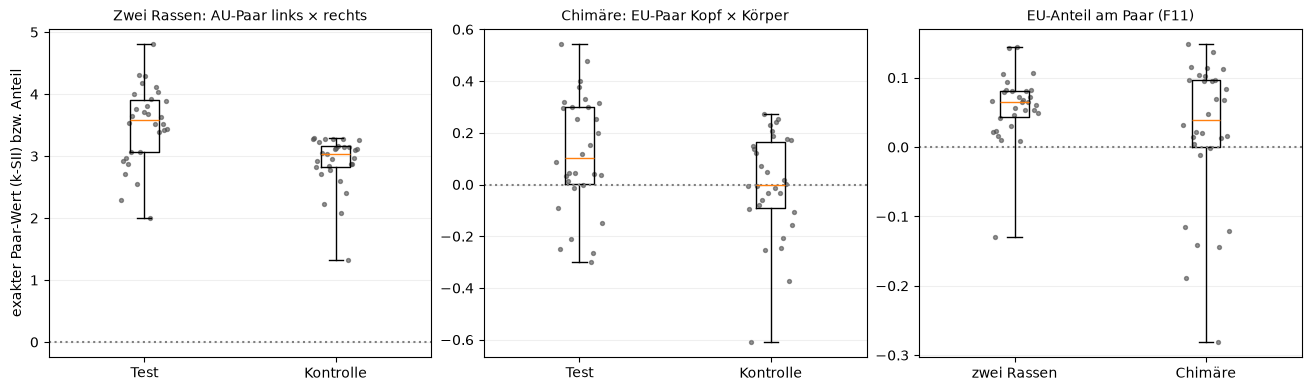

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, (values, title) in zip(
    axes,
    (
        ((au_test, au_control), "Zwei Rassen: AU-Paar links × rechts"),
        ((eu_test, eu_control), "Chimäre: EU-Paar Kopf × Körper"),
        ((share_two[np.isfinite(share_two)], share_chimera[np.isfinite(share_chimera)]), "EU-Anteil am Paar (F11)"),
    ),
    strict=True,
):
    ax.boxplot(values, whis=(0, 100))
    for position, v in enumerate(values, start=1):
        ax.scatter(np.full(len(v), position) + np.linspace(-0.12, 0.12, len(v)), v, s=8, alpha=0.6, color="0.3")
    ax.axhline(0, color="0.5", linestyle=":")
    ax.set_xticks([1, 2], ["Test", "Kontrolle"] if "Anteil" not in title else ["zwei Rassen", "Chimäre"])
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("exakter Paar-Wert (k-SII) bzw. Anteil")
fig.savefig(FIGURES / "ground_truth_paare.png", dpi=110)
plt.show()

## 6. Stufe 2, fein wie im Alltag: F8 mit 16 SLIC-Superpixeln

Jetzt geben wir der Erklärung die Teile **nicht** vor. SLIC zerlegt das Testbild wie jedes andere Bild in 16
Superpixel, und der Explainer rechnet wie in 03-1 (k-SII bis Ordnung 2, Budget 1000, dazu Shapley-Werte).

- **Superpixel des Flickens:** das Superpixel, das die meisten Pixel des Flickens enthält.
- **Treffer:** Dieses Superpixel hat von allen 16 den **höchsten** Shapley-Wert für EU. Zufall wäre 1/16 ≈ 6 %.
- Dazu, wie sauber SLIC den Flicken trifft: Anteil des Flickens in diesem Superpixel.

Das ist der teure Teil: etwa 1000 Transformer-Läufe je Bild. Die Läufe werden gespeichert; ein zweiter Durchlauf des
Notebooks braucht keine.

In [10]:
start, fine = time.perf_counter(), {}
for variant in ("test", "kontrolle"):
    for k in range(N_FINE):
        t = pattern[variant][k]
        regions = make_regions(t.image, "slic", settings.N_PLAYERS)
        fine[(variant, k)], _ = explain(t, regions, f"muster_{variant}_{k:02d}_fein", settings.BUDGET)
new = sum(e.n_forward for e in fine.values())
print(f"{len(fine)} feine Erklärungen in {time.perf_counter() - start:.0f} s; neue Transformer-Läufe: {new}.")

rows = []
for (variant, k), e in fine.items():
    t = pattern[variant][k]
    superpixel = gt.cause_superpixel(e.regions, t.cause)
    eu = e.first_order("EU")
    rows.append(
        {
            "Variante": variant,
            "Bild": t.sources["Bild"],
            "Rang des Flickens (EU)": gt.rank_of(eu, superpixel),
            "Rang des Flickens (AU)": gt.rank_of(e.first_order("AU"), superpixel),
            "φ_EU Flicken": eu[superpixel],
            "Flicken in seinem Superpixel": (e.regions[t.cause] == superpixel).mean(),
            "Superpixel besteht aus Flicken": t.cause[e.regions == superpixel].mean(),
        }
    )
fine_table = pd.DataFrame(rows)
fine_table["Treffer"] = fine_table["Rang des Flickens (EU)"] == 1
hits = fine_table.groupby("Variante")["Treffer"].mean()
F8 = hits["test"] >= RULES["F8_top1"] and hits["test"] > hits["kontrolle"]
display(
    fine_table.groupby("Variante")
    .agg(
        {
            "Treffer": "mean",
            "Rang des Flickens (EU)": "median",
            "Rang des Flickens (AU)": "median",
            "φ_EU Flicken": "median",
            "Flicken in seinem Superpixel": "median",
            "Superpixel besteht aus Flicken": "median",
        }
    )
    .style.format(
        {
            "Treffer": "{:.0%}",
            "Rang des Flickens (EU)": "{:.1f}",
            "Rang des Flickens (AU)": "{:.1f}",
            "φ_EU Flicken": "{:+.4f}",
            "Flicken in seinem Superpixel": "{:.0%}",
            "Superpixel besteht aus Flicken": "{:.0%}",
        }
    )
)
display(
    Markdown(
        f"**F8 nach der Regel: {'gestützt' if F8 else 'nicht gestützt'}.** Der Flicken hat den höchsten EU-Wert bei "
        f"{hits['test']:.0%} der Testbilder (Regel ≥ 50 %, Zufall 6 %) und bei {hits['kontrolle']:.0%} der Kontrollen."
    )
)

40 feine Erklärungen in 11 s; neue Transformer-Läufe: 0.


,Treffer,Rang des Flickens (EU),Rang des Flickens (AU),φ_EU Flicken,Flicken in seinem Superpixel,Superpixel besteht aus Flicken
Variante,,,,,,
kontrolle,15%,4.0,4.0,+0.0103,100%,97%
test,20%,4.0,5.0,+0.0110,81%,36%


**F8 nach der Regel: nicht gestützt.** Der Flicken hat den höchsten EU-Wert bei 20% der Testbilder (Regel ≥ 50 %, Zufall 6 %) und bei 15% der Kontrollen.

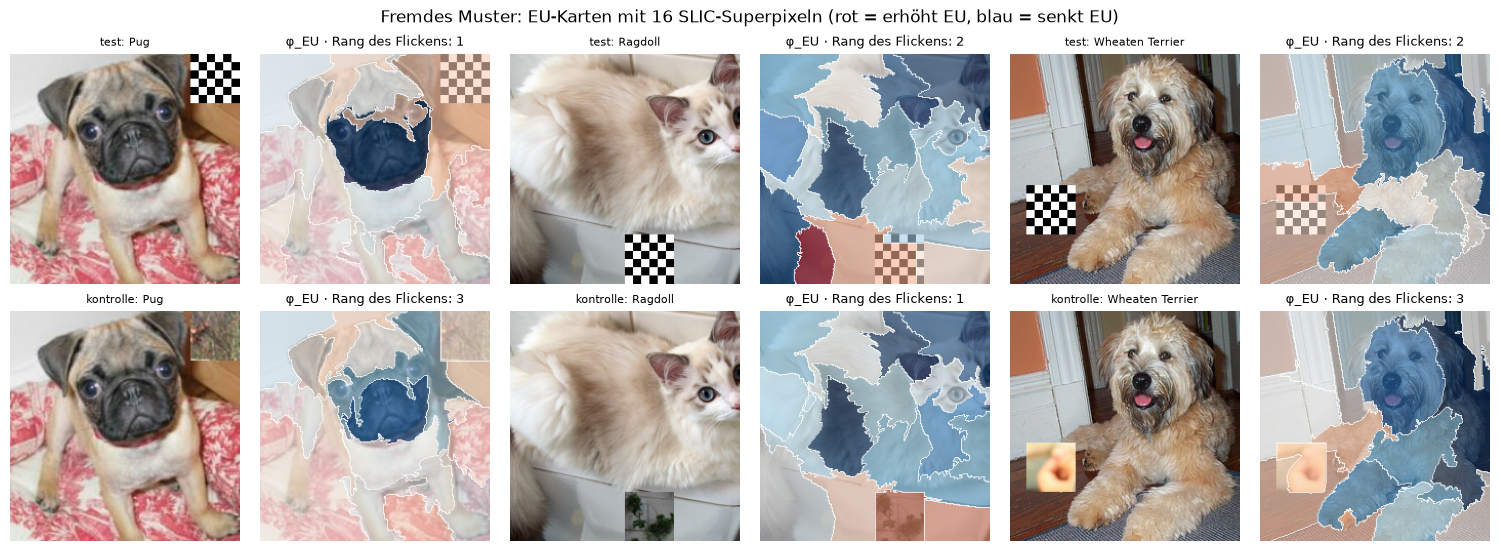

In [11]:
# Three test images and their controls: the EU maps of the normal pipeline (16 SLIC superpixels).
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4), layout="constrained")
for column in range(3):
    for row, variant in enumerate(("test", "kontrolle")):
        e = fine[(variant, column)]
        t = pattern[variant][column]
        eu = e.first_order("EU")
        vmax = max(
            np.abs(fine[("test", column)].first_order("EU")).max(),
            np.abs(fine[("kontrolle", column)].first_order("EU")).max(),
        )
        axes[row, 2 * column].imshow(t.image)
        axes[row, 2 * column].set_title(f"{variant}: {t.sources['Rasse']}", fontsize=8)
        axes[row, 2 * column].axis("off")
        superpixel = gt.cause_superpixel(e.regions, t.cause)
        show_values(
            axes[row, 2 * column + 1],
            t.image,
            e.regions,
            eu,
            vmax=vmax,
            title=f"φ_EU · Rang des Flickens: {gt.rank_of(eu, superpixel)}",
        )
fig.suptitle("Fremdes Muster: EU-Karten mit 16 SLIC-Superpixeln (rot = erhöht EU, blau = senkt EU)")
fig.savefig(FIGURES / "ground_truth_muster.png", dpi=100)
plt.show()

### 6.1 Eine Chimäre mit der normalen Pipeline

Zum Anschauen (nicht Teil der Regeln): die erste Chimäre und ihre Kontrolle mit 16 SLIC-Superpixeln, Vorhersage und
Unsicherheit nebeneinander, dazu die stärksten EU-Paare.

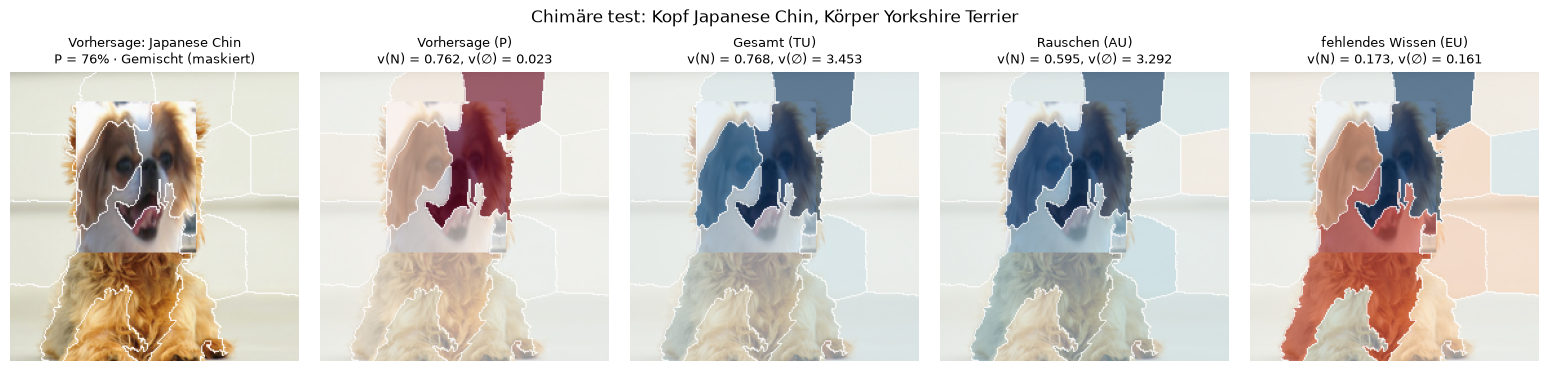

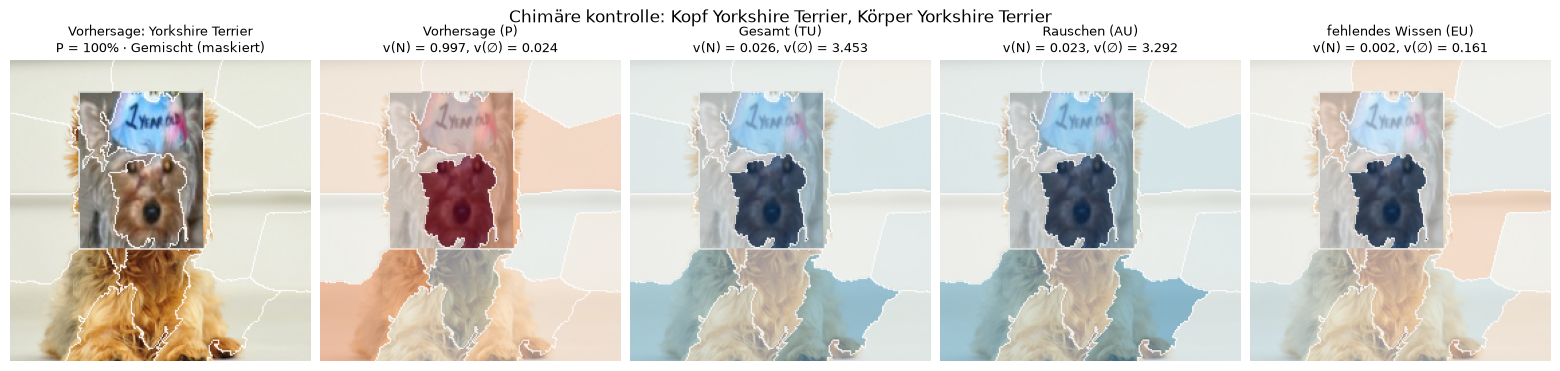

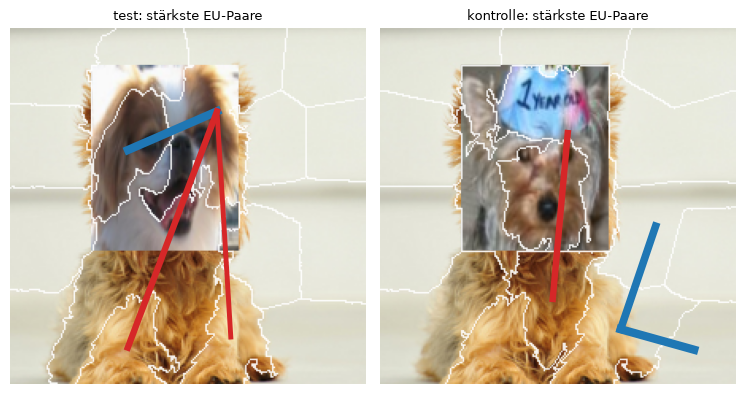

In [12]:
chimera_fine = {}
for variant in ("test", "kontrolle"):
    t = chimera[variant][0]
    regions = make_regions(t.image, "slic", settings.N_PLAYERS)
    chimera_fine[variant], _ = explain(t, regions, f"chimaere_{variant}_00_fein", settings.BUDGET)
    title = f"Chimäre {variant}: Kopf {t.sources['Rasse Kopf']}, Körper {t.sources['Rasse Körper']}"
    fig = plot_prediction_and_uncertainty(chimera_fine[variant], title=title)
    if variant == "test":
        fig.savefig(FIGURES / "ground_truth_chimaere.png", dpi=100)
    plt.show()
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.8), layout="constrained")
for ax, variant in zip(axes, ("test", "kontrolle"), strict=True):
    plot_pairs(chimera_fine[variant], "EU", ax=ax)
    ax.set_title(f"{variant}: stärkste EU-Paare", fontsize=9)
plt.show()

## 7. Mehr shapiq I: Hängt das Chimären-Paar am Index? (F12)

Bisher haben wir die Paare mit **k-SII** gemessen, wie in 03-1. shapiq kennt aber mehrere Indizes. Mit 2 oder 3
groben Spielern rechnet shapiq jeden davon **exakt**, aus denselben 4 oder 8 Koalitionen. Es kostet also keinen
einzigen neuen Transformer-Lauf.

| Index | Was er misst | Paar Kopf × Körper bei drei Spielern |
|---|---|---|
| **Möbius** | zerlegt das Spiel genau in „reine“ Effekte jeder Teilmenge, auch einen eigenen Dreier-Term | v(Kopf+Körper) − v(Kopf) − v(Körper) + v(∅), Hintergrund ausgeblendet |
| **k-SII** | Shapley-Werte, ergänzt um Paare (unser Standard) | Möbius-Paar **+ ½** Dreier-Term |
| **STII** (Shapley-Taylor) | gibt alles, was über Paare hinausgeht, gleichmäßig an die Paare | Möbius-Paar **+ ⅓** Dreier-Term |
| **FSII** (Faithful) | die beste Näherung des ganzen Spiels nur aus Einzelwerten und Paaren | Möbius-Paar **+ ½** Dreier-Term |

Der **Dreier-Term** ist der Teil, den Kopf, Körper und Hintergrund nur **alle zusammen** haben. Die Indizes
unterscheiden sich hier also nur darin, wie viel davon sie dem Paar Kopf × Körper zuschlagen. (Die Anteile ½ und ⅓
prüft ein Test in `tests/test_explainer.py`.) Bei **zwei** Spielern gibt es keinen Dreier-Term: Dann müssen alle vier
Indizes **genau dasselbe** Paar liefern. Das prüfen wir unten bei „zwei Rassen“.

**Warum das wichtig ist:** In den Grenzen stand bisher, dass das k-SII-Paar einen Teil des Dreier-Terms enthält.
Möbius trennt beides sauber. Bleibt das Paar auch bei Möbius positiv, liegt das fehlende Wissen wirklich in der
Kombination Kopf × Körper und nicht im Zusammenspiel mit dem Hintergrund.

In [13]:
INDICES = ("k-SII", "STII", "FSII", "Moebius")
start, by_index = time.perf_counter(), {}
for kind in ("zwei_rassen", "chimaere"):
    for variant in ("test", "kontrolle"):
        for k, t in enumerate(tests[kind][variant]):
            for index in INDICES:
                # Same tag as in section 3: the coalitions come from the disk cache.
                explanation, features = explain(t, t.players, f"{kind}_{variant}_{k:02d}_grob", 2**t.n_players, index)
                by_index[(kind, variant, k, index)] = explanation
new = sum(e.n_forward for e in by_index.values())
print(f"{len(by_index)} exakte Erklärungen in {time.perf_counter() - start:.0f} s; neue Transformer-Läufe: {new}.")


def index_pair(kind: str, variant: str, index: str, quantity: str = "EU") -> np.ndarray:
    # Exact pair value of players 0 and 1 (Kopf x Körper, links x rechts) for every image.
    return np.array([by_index[(kind, variant, k, index)].pairs(quantity)[0, 1] for k in range(N_IMAGES)])


# Built-in check 1: with two players every index gives the same pair, v(12) - v(1) - v(2) + v(empty).
for variant in ("test", "kontrolle"):
    for quantity in ("P", "TU", "AU", "EU"):
        for index in INDICES:
            assert np.allclose(
                index_pair("zwei_rassen", variant, index, quantity), pair("zwei_rassen", variant, quantity)
            )
# Built-in check 2: with three players the pairs differ only by their share of the three-way term m(012).
SHARE_OF_THREE_WAY = {"k-SII": 1 / 2, "STII": 1 / 3, "FSII": 1 / 2, "Moebius": 0.0}
three_way = {
    v: np.array([by_index[("chimaere", v, k, "Moebius")].values["EU"][(0, 1, 2)] for k in range(N_IMAGES)])
    for v in ("test", "kontrolle")
}
for variant in ("test", "kontrolle"):
    for index, share in SHARE_OF_THREE_WAY.items():
        expected = index_pair("chimaere", variant, "Moebius") + share * three_way[variant]
        assert np.allclose(index_pair("chimaere", variant, index), expected, atol=1e-12)
print("Zwei Rassen: alle vier Indizes liefern dasselbe Paar. Chimäre: Paare = Möbius-Paar + Anteil am Dreier-Term.")

rows = []
for index in INDICES:
    test, control = index_pair("chimaere", "test", index), index_pair("chimaere", "kontrolle", index)
    rows.append(
        {
            "Index": index,
            "Median Chimäre": np.median(test),
            "Median Kontrolle": np.median(control),
            "Anteil > 0 Chimäre": (test > 0).mean(),
            "Anteil > 0 Kontrolle": (control > 0).mean(),
            "Chimäre > eigene Kontrolle": (test > control).mean(),
            "Regel erfüllt": (test > 0).mean() >= RULES["F10_positive"] and np.median(test) > np.median(control),
        }
    )
index_table = pd.DataFrame(rows).set_index("Index")
F12 = bool(index_table["Regel erfüllt"].all())
display(Markdown("**EU-Paar Kopf × Körper, exakt, je Index** (30 Chimären und 30 Kontrollen)"))
display(
    index_table.style.format(
        {
            "Median Chimäre": "{:+.4f}",
            "Median Kontrolle": "{:+.4f}",
            "Anteil > 0 Chimäre": "{:.0%}",
            "Anteil > 0 Kontrolle": "{:.0%}",
            "Chimäre > eigene Kontrolle": "{:.0%}",
        }
    )
)
display(
    Markdown(
        f"**F12 nach der Regel: {'gestützt' if F12 else 'nicht gestützt'}.** "
        f"Dreier-Term Kopf × Körper × Hintergrund für EU (Möbius): Median {np.median(three_way['test']):+.4f} "
        f"bei den Chimären, {np.median(three_way['kontrolle']):+.4f} bei den Kontrollen; positiv bei "
        f"{(three_way['test'] > 0).mean():.0%} der Chimären."
    )
)

480 exakte Erklärungen in 7 s; neue Transformer-Läufe: 0.
Zwei Rassen: alle vier Indizes liefern dasselbe Paar. Chimäre: Paare = Möbius-Paar + Anteil am Dreier-Term.


**EU-Paar Kopf × Körper, exakt, je Index** (30 Chimären und 30 Kontrollen)

,Median Chimäre,Median Kontrolle,Anteil > 0 Chimäre,Anteil > 0 Kontrolle,Chimäre > eigene Kontrolle,Regel erfüllt
Index,,,,,,
k-SII,+0.1042,-0.0019,73%,50%,77%,True
STII,+0.0520,+0.0005,60%,50%,77%,False
FSII,+0.1042,-0.0019,73%,50%,77%,True
Moebius,-0.0145,-0.0757,50%,33%,73%,False


**F12 nach der Regel: nicht gestützt.** Dreier-Term Kopf × Körper × Hintergrund für EU (Möbius): Median +0.1972 bei den Chimären, +0.2348 bei den Kontrollen; positiv bei 93% der Chimären.

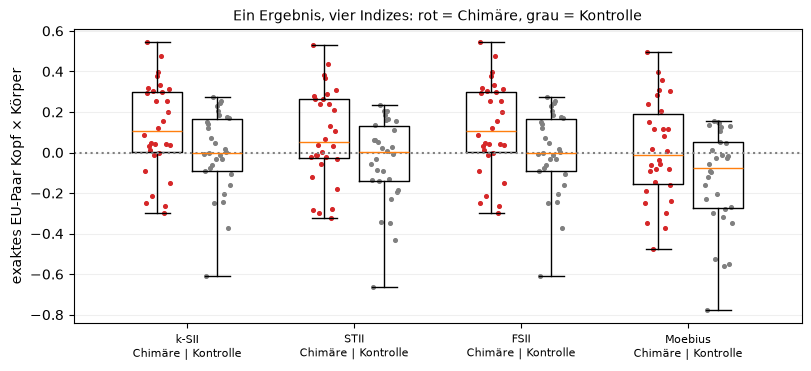

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
for number, index in enumerate(INDICES):
    for offset, variant, colour in ((-0.18, "test", "tab:red"), (0.18, "kontrolle", "0.5")):
        values = index_pair("chimaere", variant, index)
        position = number + offset
        ax.boxplot(values, positions=[position], widths=0.3, whis=(0, 100), showfliers=False)
        ax.scatter(np.full(len(values), position) + np.linspace(-0.08, 0.08, len(values)), values, s=7, color=colour)
ax.axhline(0, color="0.5", linestyle=":")
ax.set_xticks(range(len(INDICES)), [f"{index}\nChimäre | Kontrolle" for index in INDICES], fontsize=8)
ax.set_ylabel("exaktes EU-Paar Kopf × Körper")
ax.set_title("Ein Ergebnis, vier Indizes: rot = Chimäre, grau = Kontrolle", fontsize=10)
ax.grid(axis="y", alpha=0.2)
fig.savefig(FIGURES / "ground_truth_indizes.png", dpi=110)
plt.show()

### 7.1 Woher kommt der große Dreier-Term? (beschreibend, nach dem Ergebnis ergänzt)

Möbius zerlegt das Spiel in Terme, die sich gegenseitig ausgleichen. Um sie zu verstehen, schauen wir direkt auf die
acht Spielwerte, aus denen sie entstehen: die EU für jede Kombination sichtbarer Teile (Median über die 30 Bilder).

In [15]:
rows = []
for row, coalition in enumerate(gt.all_coalitions(3)):
    visible = [name for name, shown in zip(gt.CHIMERA_PLAYERS, coalition, strict=True) if shown]
    rows.append(
        {
            "sichtbar": " + ".join(visible) if visible else "(nichts)",
            **{
                variant: np.median([coarse[("chimaere", variant, k)]["table"]["EU"][row] for k in range(N_IMAGES)])
                for variant in ("test", "kontrolle")
            },
        }
    )
display(Markdown("**EU je Koalition** (Median über 30 Bilder; Spalten: Chimäre und Kontrolle)"))
display(
    pd.DataFrame(rows)
    .set_index("sichtbar")
    .rename(columns={"test": "Chimäre", "kontrolle": "Kontrolle"})
    .style.format("{:.4f}")
)

terms = {"Kopf": (0,), "Körper": (1,), "Hintergrund": (2,), "Kopf × Körper": (0, 1), "Kopf × Hintergrund": (0, 2)}
terms |= {"Körper × Hintergrund": (1, 2), "Kopf × Körper × Hintergrund": (0, 1, 2)}
rows = []
for label, subset in terms.items():
    values = {
        variant: np.array([by_index[("chimaere", variant, k, "Moebius")].values["EU"][subset] for k in range(N_IMAGES)])
        for variant in ("test", "kontrolle")
    }
    rows.append(
        {
            "Möbius-Term": label,
            "Chimäre": np.median(values["test"]),
            "Kontrolle": np.median(values["kontrolle"]),
            "Chimäre > eigene Kontrolle": (values["test"] > values["kontrolle"]).mean(),
        }
    )
display(Markdown("**Möbius-Terme für EU** (Median über 30 Bilder)"))
display(
    pd.DataFrame(rows)
    .set_index("Möbius-Term")
    .style.format({"Chimäre": "{:+.4f}", "Kontrolle": "{:+.4f}", "Chimäre > eigene Kontrolle": "{:.0%}"})
)

**EU je Koalition** (Median über 30 Bilder; Spalten: Chimäre und Kontrolle)

,Chimäre,Kontrolle
sichtbar,,
(nichts),0.1609,0.1609
Kopf,0.1081,0.0258
Körper,0.1161,0.1563
Kopf + Körper,0.1910,0.0037
Hintergrund,0.3224,0.3146
Kopf + Hintergrund,0.0863,0.0235
Körper + Hintergrund,0.1085,0.1056
Kopf + Körper + Hintergrund,0.1689,0.0035


**Möbius-Terme für EU** (Median über 30 Bilder)

,Chimäre,Kontrolle,Chimäre > eigene Kontrolle
Möbius-Term,,,
Kopf,-0.0528,-0.1352,57%
Körper,-0.0448,-0.0046,67%
Hintergrund,+0.1615,+0.1536,50%
Kopf × Körper,-0.0145,-0.0757,73%
Kopf × Hintergrund,-0.1824,-0.1774,57%
Körper × Hintergrund,-0.1920,-0.1655,50%
Kopf × Körper × Hintergrund,+0.1972,+0.2348,53%


## 8. Mehr shapiq II: Findet die normale Pipeline das Chimären-Paar? (F13)

In Abschnitt 6.1 haben wir **eine** Chimäre fein erklärt und nur angeschaut. Jetzt erklären wir die ersten 20 Chimären
und ihre 20 Kontrollen genau wie in 03-1: 16 SLIC-Superpixel, k-SII bis Ordnung 2, Budget 1000. Wir geben der
Erklärung die Teile also **nicht** vor.

- **Zuordnung:** Jedes Superpixel gehört zu dem groben Teil (Kopf, Körper, Hintergrund), der die meisten seiner Pixel
  hat (`gt.superpixel_parts`).
- **Kennzahl:** die Summe der EU-Paare zwischen **allen** Kopf- und **allen** Körper-Superpixeln
  (`gt.group_pair_sum`). Sie ist das feine Gegenstück zum groben Paar Kopf × Körper.
- **Dazu, nur beschreibend:** dieselbe Summe mit **FSII**. shapiq schätzt FSII (`RegressionFSII`) aus **denselben**
  1000 Koalitionen wie k-SII (geprüft). Es kostet also keinen neuen Transformer-Lauf.

Das ist wieder der teure Teil: etwa 1000 Transformer-Läufe je Bild. Die Läufe werden gespeichert.

In [16]:
start, fine_chimera = time.perf_counter(), {}
new = {"k-SII": 0, "FSII": 0}
for variant in ("test", "kontrolle"):
    for k in range(N_FINE):
        t = chimera[variant][k]
        regions = make_regions(t.image, "slic", settings.N_PLAYERS)
        tag = f"chimaere_{variant}_{k:02d}_fein"  # k = 0 was already explained in section 6.1
        fine_chimera[(variant, k)] = {}
        for index in ("k-SII", "FSII"):
            fine_chimera[(variant, k)][index], _ = explain(t, regions, tag, settings.BUDGET, index)
            new[index] += fine_chimera[(variant, k)][index].n_forward
print(
    f"{len(fine_chimera)} Bilder fein erklärt in {time.perf_counter() - start:.0f} s; neue Transformer-Läufe: "
    f"{new['k-SII']} für k-SII, {new['FSII']} für FSII."
)

rows = []
for (variant, k), result in fine_chimera.items():
    t, e = chimera[variant][k], result["k-SII"]
    parts = gt.superpixel_parts(e.regions, t.players)  # 0 = Kopf, 1 = Körper, 2 = Hintergrund
    row = {
        "Variante": variant,
        "k": k,
        "Kopf-Superpixel": int((parts == 0).sum()),
        "Körper-Superpixel": int((parts == 1).sum()),
        # How cleanly SLIC follows the pasted head: share of the head pixels that lie in head superpixels.
        "Kopf-Pixel in Kopf-Superpixeln": (parts[e.regions][t.players == 0] == 0).mean(),
        "grobes Paar (k-SII)": coarse[("chimaere", variant, k)]["explanation"].pairs("EU")[0, 1],
    }
    for index in ("k-SII", "FSII"):
        pairs_eu = result[index].pairs("EU")
        row[f"Kopf × Körper ({index})"] = gt.group_pair_sum(pairs_eu, parts, 0, 1)
    row["Kopf × Hintergrund (k-SII)"] = gt.group_pair_sum(e.pairs("EU"), parts, 0, 2)
    row["Körper × Hintergrund (k-SII)"] = gt.group_pair_sum(e.pairs("EU"), parts, 1, 2)
    # The decomposition carries over to the fine pairs (budget 1000 > 137 unknowns).
    assert np.allclose(e.pairs("TU"), e.pairs("AU") + e.pairs("EU"), atol=1e-6)
    rows.append(row)
fine_chimera_table = pd.DataFrame(rows)

fine_test = fine_chimera_table.query("Variante == 'test'")["Kopf × Körper (k-SII)"].to_numpy()
fine_control = fine_chimera_table.query("Variante == 'kontrolle'")["Kopf × Körper (k-SII)"].to_numpy()
empty_groups = int(
    ((fine_chimera_table["Kopf-Superpixel"] == 0) | (fine_chimera_table["Körper-Superpixel"] == 0)).sum()
)
# An image whose head or body has no superpixel has an empty sum (0) and therefore counts as "not positive".
F13 = (fine_test > 0).mean() >= RULES["F10_positive"] and np.median(fine_test) > np.median(fine_control)

summary_columns = {
    "Kopf × Körper (k-SII)": ["median", lambda v: (v > 0).mean()],
    "Kopf × Körper (FSII)": ["median", lambda v: (v > 0).mean()],
    "Kopf × Hintergrund (k-SII)": ["median"],
    "Körper × Hintergrund (k-SII)": ["median"],
    "Kopf-Superpixel": ["median"],
    "Körper-Superpixel": ["median"],
    "Kopf-Pixel in Kopf-Superpixeln": ["median"],
}
fine_summary = fine_chimera_table.groupby("Variante", sort=False).agg(summary_columns)
fine_summary.columns = [
    f"{column} {'Median' if how == 'median' else 'Anteil > 0'}" for column, how in fine_summary.columns
]
display(Markdown("**Feine EU-Paare, nach groben Teilen zusammengefasst** (20 Chimären, 20 Kontrollen)"))
shares = [row for row in fine_summary.columns if "Anteil" in row or "Pixel" in row]
counts = [row for row in fine_summary.columns if row.endswith("Superpixel Median")]
display(
    fine_summary.T.style.format("{:+.4f}")
    .format("{:.0%}", subset=pd.IndexSlice[shares, :])
    .format("{:.0f}", subset=pd.IndexSlice[counts, :])
)
paired_fine = (fine_test > fine_control).mean()
paired_difference = np.median(fine_test - fine_control)  # test k and control k share body and background
largest = (
    fine_chimera_table.query("Variante == 'test'")[
        ["Kopf × Körper (k-SII)", "Kopf × Hintergrund (k-SII)", "Körper × Hintergrund (k-SII)"]
    ]
    .idxmax(axis=1)
    .eq("Kopf × Körper (k-SII)")
    .mean()
)
agreement = fine_chimera_table[["grobes Paar (k-SII)", "Kopf × Körper (k-SII)"]].corr(method="spearman").iloc[0, 1]
display(
    Markdown(
        f"**F13 nach der Regel: {'gestützt' if F13 else 'nicht gestützt'}.** Die feine Summe Kopf × Körper ist bei "
        f"{(fine_test > 0).mean():.0%} der Chimären positiv (Regel ≥ 67 %; Kontrolle {(fine_control > 0).mean():.0%}); "
        f"Median {np.median(fine_test):+.4f} gegen {np.median(fine_control):+.4f}. Bilder ohne Kopf- oder "
        f"Körper-Superpixel: {empty_groups}.\n\n"
        f"Beschreibend: Bei {paired_fine:.0%} der Chimären ist die Summe größer als bei der eigenen Kontrolle "
        f"(Median des Unterschieds {paired_difference:+.4f}); bei "
        f"{largest:.0%} ist Kopf × Körper die größte der drei Summen. Grob und fein stimmen in der Reihenfolge der "
        f"Bilder überein mit ρ = {agreement:.2f} (Spearman, 40 Bilder)."
    )
)

40 Bilder fein erklärt in 18 s; neue Transformer-Läufe: 0 für k-SII, 0 für FSII.


**Feine EU-Paare, nach groben Teilen zusammengefasst** (20 Chimären, 20 Kontrollen)

Variante,test,kontrolle
Kopf × Körper (k-SII) Median,+0.0152,-0.1717
Kopf × Körper (k-SII) Anteil > 0,50%,10%
Kopf × Körper (FSII) Median,+0.1299,+0.0248
Kopf × Körper (FSII) Anteil > 0,70%,60%
Kopf × Hintergrund (k-SII) Median,-0.2747,-0.3172
Körper × Hintergrund (k-SII) Median,-0.4102,-0.3549
Kopf-Superpixel Median,4,3
Körper-Superpixel Median,4,5
Kopf-Pixel in Kopf-Superpixeln Median,87%,88%


**F13 nach der Regel: nicht gestützt.** Die feine Summe Kopf × Körper ist bei 50% der Chimären positiv (Regel ≥ 67 %; Kontrolle 10%); Median +0.0152 gegen -0.1717. Bilder ohne Kopf- oder Körper-Superpixel: 1.

Beschreibend: Bei 85% der Chimären ist die Summe größer als bei der eigenen Kontrolle (Median des Unterschieds +0.2349); bei 80% ist Kopf × Körper die größte der drei Summen. Grob und fein stimmen in der Reihenfolge der Bilder überein mit ρ = 0.35 (Spearman, 40 Bilder).

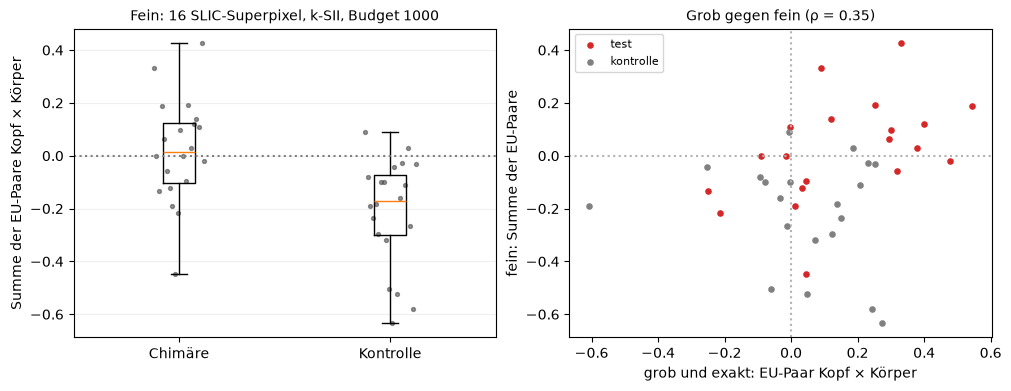

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for ax, index in zip(axes[:1], ("k-SII",), strict=True):
    values = [
        fine_chimera_table.query(f"Variante == '{v}'")[f"Kopf × Körper ({index})"].to_numpy()
        for v in ("test", "kontrolle")
    ]
    ax.boxplot(values, whis=(0, 100))
    for position, v in enumerate(values, start=1):
        ax.scatter(np.full(len(v), position) + np.linspace(-0.12, 0.12, len(v)), v, s=8, alpha=0.6, color="0.3")
    ax.axhline(0, color="0.5", linestyle=":")
    ax.set_xticks([1, 2], ["Chimäre", "Kontrolle"])
    ax.set_ylabel("Summe der EU-Paare Kopf × Körper")
    ax.set_title(f"Fein: 16 SLIC-Superpixel, {index}, Budget 1000", fontsize=10)
    ax.grid(axis="y", alpha=0.2)
for variant, colour in (("test", "tab:red"), ("kontrolle", "0.5")):
    part = fine_chimera_table.query(f"Variante == '{variant}'")
    axes[1].scatter(part["grobes Paar (k-SII)"], part["Kopf × Körper (k-SII)"], color=colour, s=14, label=variant)
axes[1].axhline(0, color="0.7", linestyle=":")
axes[1].axvline(0, color="0.7", linestyle=":")
axes[1].set_xlabel("grob und exakt: EU-Paar Kopf × Körper")
axes[1].set_ylabel("fein: Summe der EU-Paare")
axes[1].set_title(f"Grob gegen fein (ρ = {agreement:.2f})", fontsize=10)
axes[1].legend(fontsize=8)
fig.savefig(FIGURES / "ground_truth_chimaere_fein.png", dpi=110)
plt.show()

## 9. Mehr shapiq III: die Chimäre in shapiq-Plots

shapiq bringt eigene Plots für `InteractionValues` mit. Für die erste Chimäre (dieselbe wie in 3.1 und 6.1) und ihre
Kontrolle:

- **`upset_plot`** (grob, exakt, Möbius für EU): ein Balken je Teilmenge der drei Teile. Unten steht, welche Teile
  dazugehören. Man sieht direkt, ob das fehlende Wissen allein im Kopf, allein im Körper oder in der **Kombination**
  steckt.
- **`force_plot`** (grob, exakt, k-SII für EU): Wie wird aus der EU des leeren Bildes die EU des ganzen Bildes? Jeder
  Pfeil ist ein Einzelwert oder ein Paar.
- **`si_graph_plot`** (fein, 16 SLIC-Superpixel, k-SII für EU): Jeder Knoten ist ein Superpixel, gezeigt als
  Bildausschnitt. Die Größe des Kreises ist sein Einzelwert, die Linien sind die stärksten Paare (rot = erhöht EU, blau
  = senkt EU). Der farbige Rahmen sagt, zu welchem Teil das Superpixel gehört: **orange = Kopf, grün = Körper, grau =
  Hintergrund**.

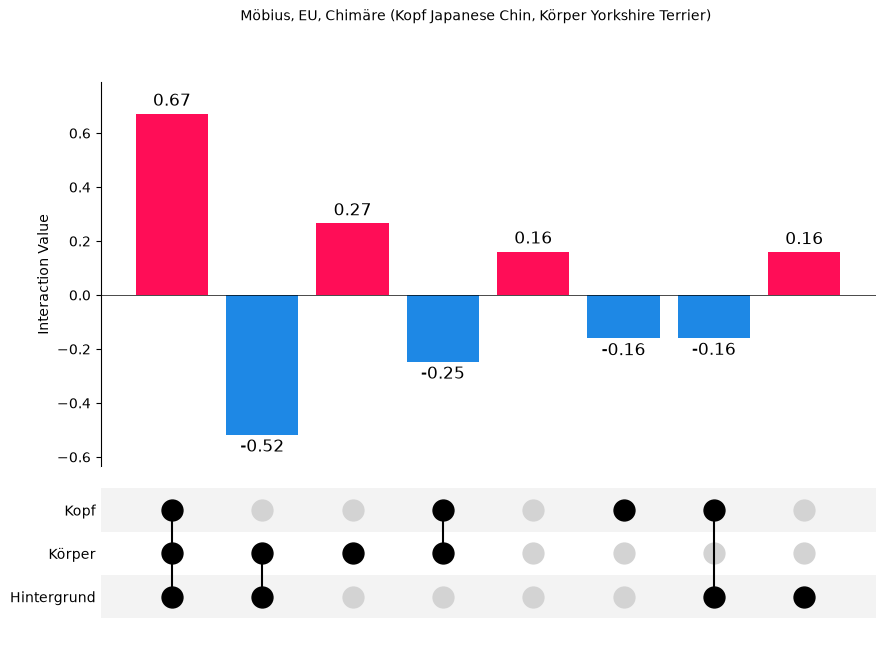

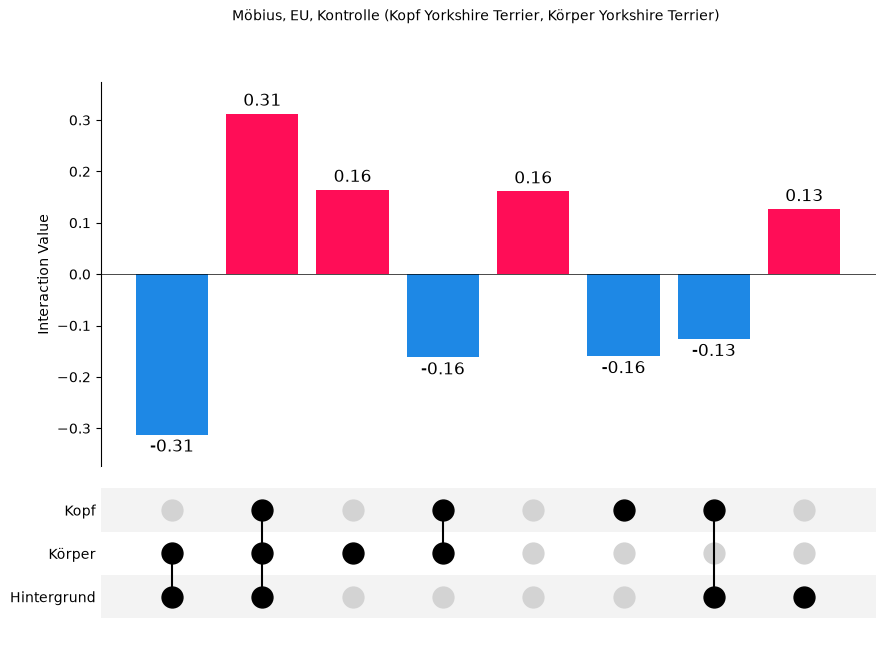

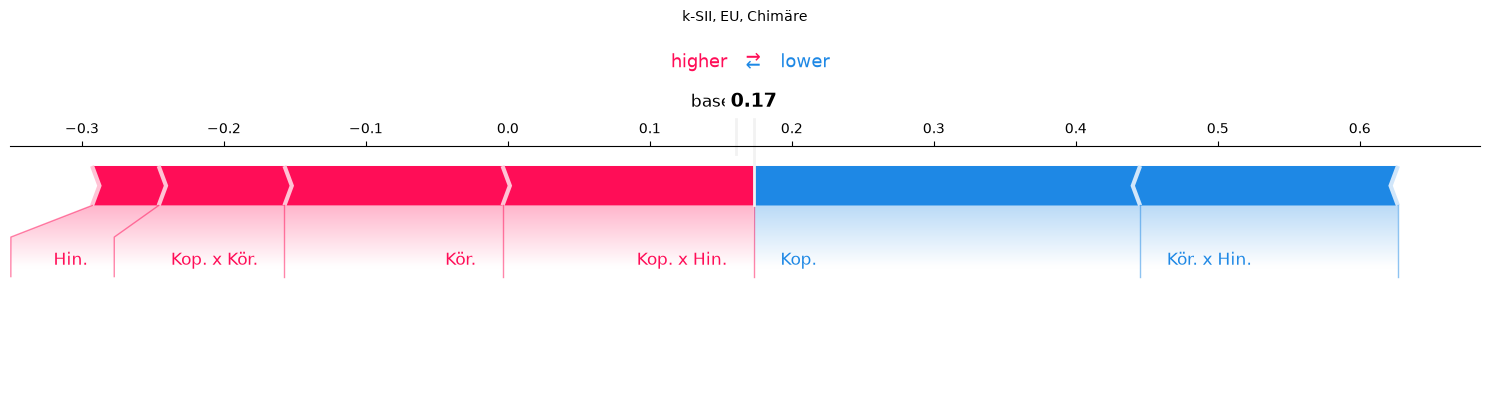

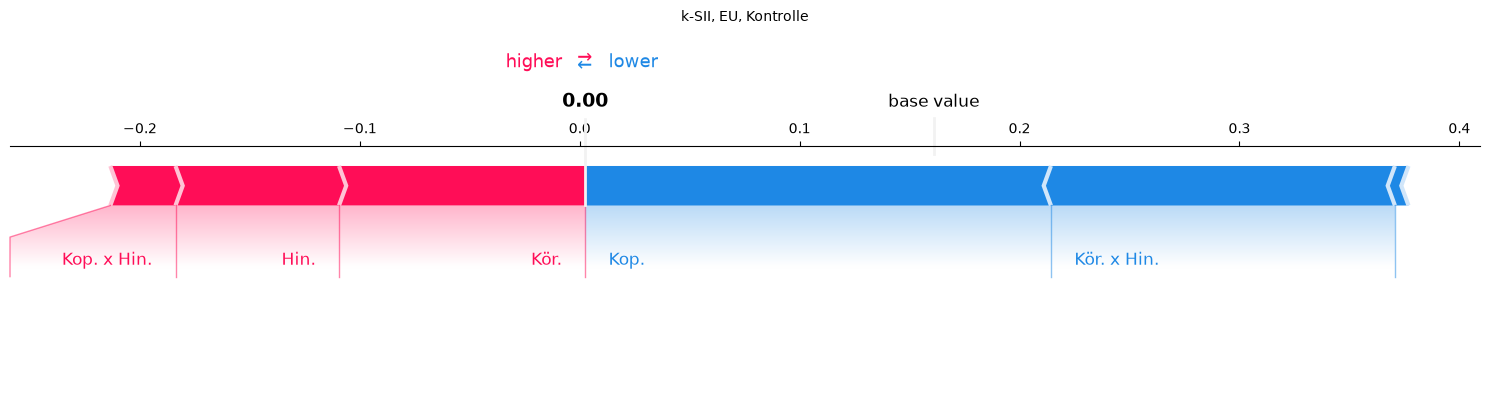

In [18]:
names = list(gt.CHIMERA_PLAYERS)
for variant in ("test", "kontrolle"):
    t = chimera[variant][0]
    label = f"Kopf {t.sources['Rasse Kopf']}, Körper {t.sources['Rasse Körper']}"
    fig = shapiq.plot.upset_plot(by_index[("chimaere", variant, 0, "Moebius")].values["EU"], feature_names=names)
    fig.suptitle(f"Möbius, EU, {'Chimäre' if variant == 'test' else 'Kontrolle'} ({label})", fontsize=10)
    if variant == "test":
        fig.savefig(FIGURES / "ground_truth_upset.png", dpi=110, bbox_inches="tight")
    plt.show()

for variant in ("test", "kontrolle"):
    fig = shapiq.plot.force_plot(by_index[("chimaere", variant, 0, "k-SII")].values["EU"], feature_names=names)
    fig.suptitle(f"k-SII, EU, {'Chimäre' if variant == 'test' else 'Kontrolle'}", fontsize=10, y=1.02)
    plt.show()

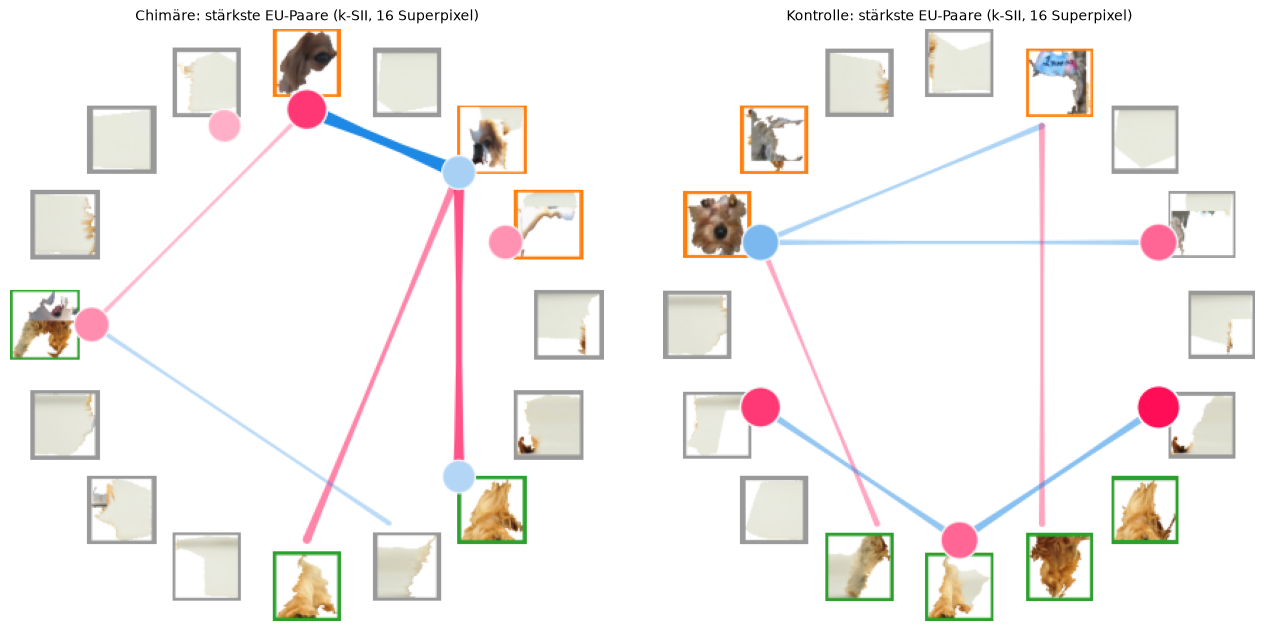

In [19]:
PART_COLOURS = ("tab:orange", "tab:green", "0.6")  # Kopf, Körper, Hintergrund
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), layout="constrained")
for ax, variant in zip(axes, ("test", "kontrolle"), strict=True):
    t, e = chimera[variant][0], fine_chimera[(variant, 0)]["k-SII"]
    parts = gt.superpixel_parts(e.regions, t.players)
    patches = superpixel_patches(t.image, e.regions, frame_colors=[PART_COLOURS[p] for p in parts])
    # si_graph_plot draws into a figure of its own; we copy that picture into our panel.
    graph, graph_ax = shapiq.plot.si_graph_plot(
        e.values["EU"],
        n_interactions=12,
        feature_image_patches=patches,
        feature_image_patches_size=0.14,
        size_factor=1.5,
    )
    graph_ax.set_adjustable("box")  # keep the limits below (the graph is drawn with equal aspect)
    for get, set_limits in ((graph_ax.get_xlim, graph_ax.set_xlim), (graph_ax.get_ylim, graph_ax.set_ylim)):
        low, high = get()  # a little more room, so that the pictures at the edge are not cut off
        set_limits(low - 0.12 * (high - low), high + 0.12 * (high - low))
    graph.canvas.draw()
    picture = np.asarray(graph.canvas.buffer_rgba())
    plt.close(graph)
    rows_, cols_ = np.nonzero(picture[..., :3].min(axis=2) < 250)  # crop the white margin around the graph
    ax.imshow(picture[rows_.min() : rows_.max() + 1, cols_.min() : cols_.max() + 1])
    ax.set_title(
        f"{'Chimäre' if variant == 'test' else 'Kontrolle'}: stärkste EU-Paare (k-SII, 16 Superpixel)", fontsize=10
    )
    ax.axis("off")
fig.savefig(FIGURES / "ground_truth_si_graph.png", dpi=100)
plt.show()

## 10. Ergebnis

In [20]:
verdicts = pd.DataFrame(
    {
        "Frage": [
            "F8 feine EU-Karte findet das fremde Muster",
            "F9 zwei Rassen zeigen ein AU-Paar",
            "F10 Chimäre zeigt ein EU-Paar",
            "F11 EU-Anteil am Paar: Chimäre > zwei Rassen",
            "F12 Chimären-Paar bei allen vier Indizes",
            "F13 Chimären-Paar mit 16 SLIC-Superpixeln",
        ],
        "Kennzahl": [
            f"Treffer {hits['test']:.0%} (Kontrolle {hits['kontrolle']:.0%}; Zufall 6 %)",
            f"positiv {(au_test > 0).mean():.0%}; Median {np.median(au_test):+.3f} gegen {np.median(au_control):+.3f}",
            f"positiv {(eu_test > 0).mean():.0%}; Median {np.median(eu_test):+.4f} gegen {np.median(eu_control):+.4f}",
            f"Median {np.nanmedian(share_chimera):+.3f} gegen {np.nanmedian(share_two):+.3f}",
            "positiv " + ", ".join(f"{i} {r:.0%}" for i, r in index_table["Anteil > 0 Chimäre"].items()),
            (
                f"positiv {(fine_test > 0).mean():.0%}; "
                f"Median {np.median(fine_test):+.4f} gegen {np.median(fine_control):+.4f}"
            ),
        ],
        "Ergebnis": ["gestützt" if v else "nicht gestützt" for v in (F8, F9, F10, F11, F12, F13)],
    }
).set_index("Frage")
display(verdicts)

,Kennzahl,Ergebnis
Frage,,
F8 feine EU-Karte findet das fremde Muster,Treffer 20% (Kontrolle 15%; Zufall 6 %),nicht gestützt
F9 zwei Rassen zeigen ein AU-Paar,positiv 100%; Median +3.584 gegen +3.036,gestützt
F10 Chimäre zeigt ein EU-Paar,positiv 73%; Median +0.1042 gegen -0.0019,gestützt
F11 EU-Anteil am Paar: Chimäre > zwei Rassen,Median +0.039 gegen +0.065,nicht gestützt
F12 Chimären-Paar bei allen vier Indizes,"positiv k-SII 73%, STII 60%, FSII 73%, Moebius...",nicht gestützt
F13 Chimären-Paar mit 16 SLIC-Superpixeln,positiv 50%; Median +0.0152 gegen -0.1717,nicht gestützt


**Was die Ergebnisse in einfachen Worten sagen** (Zahlen aus unserem Lauf, siehe Tabellen oben)

1. **Die Chimäre erhöht das fehlende Wissen, sobald Kopf und Körper zusammen sichtbar sind (F10 gestützt).** Auf dem
   ganzen Bild hat die Chimäre im Median 0,1689 nats EU, die Kontrolle nur 0,0035. Die Tabelle in 7.1 zeigt, wann das
   passiert: Mit Kopf und Körper (ohne Hintergrund) liegt die EU bei 0,1910, bei der Kontrolle bei 0,0037. Ohne Kopf
   (Körper und Hintergrund) sind beide gleich (0,1085 gegen 0,1056). Für die Kontrolle heißt „Kopf und Körper
   zusammen“ also „jetzt bin ich sicher“, für die Chimäre „jetzt sind sich die Mitglieder uneinig“. Das exakte
   k-SII-Paar Kopf × Körper ist für EU im Median +0,1042, bei der Kontrolle −0,0019. Es ist bei 73 % der Chimären
   positiv (Kontrolle 50 %) und bei 77 % größer als bei der eigenen Kontrolle. Das ist die Bild-Version der
   „epistemischen Interaktion“ aus dem Projektplan (N1). Die Vorhersage folgt meist dem Kopf (57 %), seltener dem
   Körper (33 %).
   *Korrektur zur ersten Fassung (25.11.):* Dort stand, im Beispiel aus 3.1 steige die EU mit Kopf und Körper auf
   0,1731. Das ist der Wert des **ganzen** Bildes; Kopf und Körper ohne Hintergrund ergeben dort nur 0,0190. In diesem
   einen Beispiel kommt das fehlende Wissen also erst mit allen drei Teilen. Im Median über alle 30 Chimären reichen
   Kopf und Körper.
2. **Ob das Paar „positiv“ ist, hängt am Index; der Abstand zur Kontrolle nicht (F12 nicht gestützt).** k-SII und FSII
   liefern bei drei Spielern genau dasselbe Paar und erfüllen die Regel. STII (positiv bei 60 %) und Möbius (50 %)
   erfüllen sie nicht. Bei **allen vier** Indizes liegt der Median der Chimären aber über dem der Kontrollen, und bei 73
   bis 77 % der Chimären ist das Paar größer als bei der eigenen Kontrolle. Der Grund ist der **Dreier-Term** Kopf ×
   Körper × Hintergrund. Er ist groß und fast immer positiv (Median +0,1972, positiv bei 93 % der Chimären), aber bei
   den Kontrollen genauso groß (+0,2348). Er entsteht, weil stark ausgeblendete Bilder viel EU haben: Ist nur der
   Hintergrund sichtbar, liegt die EU bei 0,32 nats, also höher als beim ganzen Bild der Chimäre. Wie viel davon ein
   Index dem Paar gibt (k-SII ½, STII ⅓, Möbius nichts), schiebt das Paar über oder unter null. Von allen sieben
   Möbius-Termen unterscheidet sich das Paar Kopf × Körper am deutlichsten zwischen Chimäre und Kontrolle (bei 73 %
   größer; alle anderen Terme 50 bis 67 %).
   **Die Lehre:** Das Vorzeichen eines einzelnen Paar-Werts ist keine Eigenschaft des Bildes, sondern hängt am Index.
   Belastbar ist der Vergleich mit einer Kontrolle.
3. **Auch die normale Pipeline sieht den Unterschied, aber nicht als positives Paar (F13 nicht gestützt).** Mit 16
   SLIC-Superpixeln ist die Summe der EU-Paare zwischen Kopf und Körper nur bei 50 % der Chimären positiv (Regel ≥ 67 %;
   Kontrolle 10 %), Median +0,0152 gegen −0,1717. Bei 85 % der Chimären ist sie aber größer als bei der eigenen
   Kontrolle (Median des Unterschieds +0,2349), und bei 80 % ist Kopf × Körper die größte der drei Summen. Die feinen
   Paare liegen also insgesamt im Minus (bei den Kontrollen sind alle drei Summen negativ); die Chimäre hebt Kopf ×
   Körper deutlich an, meist aber nicht über null. FSII aus denselben Koalitionen ist häufiger positiv (70 %), bei den
   Kontrollen aber auch (60 %). Grob und fein ordnen die Bilder nur schwach gleich (ρ = 0,35). Mögliche Gründe
   (Vermutungen, nicht geprüft): Der Kopf zerfällt in etwa 4 Superpixel, das Paar verteilt sich also auf viele kleine
   Werte; 1000 von 65.536 Koalitionen sind eine Näherung; und wie in Punkt 2 haben stark ausgeblendete Bilder viel EU,
   was die feinen Paare nach unten zieht.
4. **Zwei Rassen zeigen ein AU-Paar (F9 gestützt), aber man muss genau hinsehen.** Wie vorab aufgeschrieben, ist das
   AU-Paar auch bei der Kontrolle immer positiv (Median +3,036), weil die zweite Hälfte nur noch wenig Neues bringt. Das
   eigentliche Signal ist der Abstand: +3,584 bei zwei Rassen, und bei 80 % der Bilder größer als bei der eigenen
   Kontrolle. Auf dem ganzen Bild steigt die AU von 0,035 auf 0,638. Hin- und hergerissen (beide Rassen ≥ 20 %) ist das
   Modell aber nur bei 13 % der Bilder; meist gewinnt die linke Hälfte (P 0,47 gegen 0,24).
5. **Die Zerlegung trennt „Widerspruch“ nicht von „nie gesehen“ (F11 nicht gestützt).** Beide Testbilder erhöhen AU
   **und** EU ähnlich stark (ganzes Bild: zwei Rassen AU 0,638 und EU 0,1314, Chimäre AU 0,664 und EU 0,1689). Der
   EU-Anteil am Paar ist bei der Chimäre sogar kleiner (0,039 gegen 0,065). Auch zwei Rassen zeigen ein deutliches
   EU-Paar (+0,2581 gegen +0,1301). Zwei mögliche Gründe (Vermutungen, nicht geprüft):
   - Unsere Konstruktion ist weniger sauber, als wir dachten. Zwei halbe Tiere nebeneinander sind für das Modell
     **auch** ein nie gesehenes Bild. Der Test „zwei Rassen“ ist also kein reiner AU-Fall.
   - Im gemischten Ensemble entsteht die EU vor allem **zwischen** ViT und DINOv2 (73 %, 03-0). Gewichten die beiden
     Netze die zwei Teile verschieden, sind sie sich uneinig, egal ob es ein Widerspruch oder eine neue Kombination ist.

   **Die Lehre:** Was als AU und was als EU zählt, entscheiden das Modell und seine Mitglieder, nicht unsere Geschichte
   über das Bild.
6. **Ein fremdes Muster erzeugt hier kein fehlendes Wissen (F8 nicht gestützt).** Die feine EU-Karte setzt den Flicken
   nur bei 20 % der Bilder auf Platz 1 (Kontrolle 15 %, Zufall 6 %). Auch grob, mit dem Flicken als eigenem Spieler,
   bekommt das Schachbrett weniger EU als der natürliche Flicken (Shapley-Wert +0,0099 gegen +0,0275). **Stufe 1 zeigt
   den Grund: Das Modell reagiert kaum.** Ist das Tier sichtbar, ändert das Schachbrett die EU im Median nur um
   +0,0003 nats; das Modell übersieht es. Ist nur der Flicken sichtbar, ist das Modell fast maximal unsicher (TU 3,36
   von höchstens 3,61), aber fast alles davon ist **AU** (3,18): Alle sechs Mitglieder sagen gemeinsam „keine Ahnung“
   und sind sich darin einig. Der natürliche Flicken allein bekommt sogar mehr EU (0,25 gegen 0,18). Der Explainer irrt
   also nicht. Er meldet richtig, dass das Modell dort kein fehlendes Wissen hat.
7. **Warum die zwei Stufen wichtig waren:** Ohne Stufe 1 hätten wir aus F8 geschlossen, dass der Explainer das Muster
   nicht findet. Mit Stufe 1 wissen wir: Der Explainer arbeitet richtig, das Modell zeigt dort einfach keine EU.
   Nebenbei: SLIC schneidet den natürlichen Flicken sauber aus (sein Superpixel besteht zu 97 % aus dem Flicken), das
   Schachbrett dagegen kaum (36 %). Vermutlich liegt das daran, dass SLIC nach Farbe gruppiert und das Schachbrett im
   Mittel grau ist.

**Was das für die Leitfrage bedeutet**

- **Welche Bildteile machen das Modell unsicher?** Bei Kombinationen, die das Modell nicht kennt, steigt das fehlende
  Wissen genau dann, wenn die Teile **zusammen** sichtbar sind. Die Erklärung zeigt das als Paar Kopf × Körper, mit
  jedem Index und auch mit 16 Superpixeln. Zuverlässig ist dabei der **Vergleich mit einer Kontrolle**; ob ein einzelnes
  Paar über null liegt, hängt am Index und an den Spielern. Einzelne Shapley-Werte würden diese Ursache auf Kopf und
  Körper verschmieren.
- **Rauschen oder fehlendes Wissen?** Die Aufteilung ist keine Eigenschaft des Bildes, sondern des Modells. Fremdes
  Material landet hier in der AU, weil sich alle Mitglieder einig sind, dass sie nichts wissen. Widersprüchliche und neue
  Kombinationen erhöhen beides. **EU ist in diesem Modell kein Alarm für Fremdes.** Das passt zum Staffordshire-Fall aus
  03-1 (EU findet sichere Fehler nicht) und zum Vorversuch an Hautbildern (gestörte Bilder machten die Modelle nicht
  unsicherer).

**Was das für unser Projekt bedeutet**

- **Ein Prüfstand für den Explainer:** Testbilder mit eingebauter Ursache, jeweils mit Kontrolle, und exakte Spiele mit
  wenigen Spielern. Er passt zu jeder probly-Methode. Naheliegender nächster Schritt (Idee B1): Zeigen auch MC Dropout
  oder eine Methode ohne Mitglieder (z. B. Evidential) das Chimären-Paar?
- **Kennzahlen immer gegen eine Kontrolle:** F12 und F13 zeigen, dass „Paar größer als null“ eine schwache Regel ist,
  weil das Grundniveau der Paare vom Index und von den Spielern abhängt. „Größer als bei der eigenen Kontrolle“ war in
  allen Varianten stabil (73 bis 85 %). Für künftige Fragen nehmen wir deshalb den Abstand zur Kontrolle als Regel.
- **Mehr shapiq:** Der Explainer rechnet jetzt jeden exakten Index (k-SII, STII, FSII, Möbius) und als Näherung k-SII,
  SII, FSII und Shapley-Werte, alle aus denselben Koalitionen. shapiqs eigene Plots (`upset_plot`, `force_plot`,
  `si_graph_plot`) zeigen die Chimäre.
- **Warum k-SII unser Standard bleibt:** Es enthält die Shapley-Werte, ist bei drei Spielern genau gleich FSII, und es
  mittelt über viele Zusammenhänge. Möbius ist exakt, hängt aber an sehr stark ausgeblendeten Bildern (z. B. nur
  Hintergrund), die das Modell kaum kennt.
- **Zwei Stufen als Standard:** Erst prüfen, ob das Modell reagiert, dann, ob die Erklärung es findet. Sonst verwechselt
  man Eigenschaften des Modells mit Fehlern der Erklärung.
- **Für Idee B3 (fremde Bilder):** In diesem Modell werden fremde Inhalte nicht über EU sichtbar. Dafür bräuchte man ein
  anderes Maß oder Mitglieder, die sich bei Fremdem wirklich widersprechen.
- **Für die Präsentation:** `figures/ground_truth_chimaere.png` (die EU-Karte färbt den Körper rot),
  `figures/ground_truth_paare.png` (Test gegen Kontrolle), `figures/ground_truth_indizes.png` (vier Indizes),
  `figures/ground_truth_upset.png` und `figures/ground_truth_si_graph.png` (shapiq-Plots der Chimäre).

**So kannst du es in der Präsentation erzählen**

> „Bei echten Fotos wissen wir nicht, ob die Karten stimmen. Deshalb haben wir Testbilder gebaut, deren Ursache wir
> kennen, jedes mit einer Kontrolle. Setzen wir den Kopf einer Rasse auf den Körper einer anderen, steigt das fehlende
> Wissen genau dann, wenn Kopf und Körper zusammen sichtbar sind. shapiq zeigt das als Paar Kopf × Körper: Bei drei von
> vier Chimären ist es größer als bei der Kontrolle, mit jedem der vier Indizes und auch mit 16 Superpixeln. Ob das
> Paar dabei über null liegt, hängt allerdings am Index. Deshalb vergleichen wir immer mit einer Kontrolle. Ein fremdes
> Schachbrett macht das Modell dagegen unsicher, aber als Rauschen: Alle Mitglieder sagen gemeinsam ‚keine Ahnung‘. EU
> ist also kein Alarm für Fremdes, und das konnten wir nur sehen, weil wir zuerst das Modell und dann die Erklärung
> geprüft haben.“

**Grenzen**

- 30 Testbilder je Test, 20 davon fein erklärt (Muster und Chimäre). Die Schwellen sind vorab gesetzte Regeln, keine
  statistischen Tests; die paarweisen Anteile sind nur beschreibend.
- F12 und F13 haben wir festgelegt, als das Ergebnis von F10 schon bekannt war. Die Regeln haben wir nach der Rechnung
  nicht geändert, auch nicht, als sich zeigte, dass „Anteil positiv“ zu feinen Paaren schlecht passt.
- Die Testbilder sind künstlich: harte Klebekanten, der Kopf-Rahmen bringt etwas Hintergrund des Kopf-Bildes mit, und
  der mittlere Streifen zeigt nicht bei jedem Bild viel vom Tier. Die Kontrollen gleichen das aus, aber nicht ganz.
  Tokens an der Grenze zweier Teile enthalten Pixel von beiden; ein „ausgeblendeter“ Kopf ist also am Rand noch ein
  wenig sichtbar.
- Nur eine Methode (`Gemischt` mit maskierten Köpfen). Die Validierungsbilder wurden beim Training der Köpfe für das
  frühe Stoppen benutzt; ganz unbekannt sind sie also nicht.
- Möbius-Terme und Paare hängen an stark ausgeblendeten Bildern (z. B. nur Hintergrund sichtbar: EU 0,32). Solche
  Eingaben kennt das Modell kaum, auch mit maskiertem Training.
- F11 vergleicht zwei verschiedene Konstruktionen (zwei gegen drei Spieler); der Vergleich ist nur grob.